# PRCP-1003 · Customer Transaction Prediction

**Domain:** Banking  **Task type:** Binary classification  **Data:** 200,000 customers × 200 anonymised numeric features

### Problem statement
* **Task 1:** Prepare a complete data analysis report on the given data.
* **Task 2:** Create a predictive model that helps the bank identify which customers will make a transaction in the future, irrespective of the amount.
* **Model comparison report:** Compare several models and recommend the best one for production.
* **Report on challenges faced:** Describe the challenges in the data and the techniques used, with reasons.

`target` = 1 means the customer made the transaction and 0 means they did not. The 200 features (`var_0` … `var_199`) are anonymised, so their business meaning is unknown.

### Contents
1. Setup
2. Data loading and quality checks
3. Data analysis report (Task 1)
4. Data preparation and feature engineering
5. Modelling experiments (Task 2)
6. Model comparison (5-fold cross-validation and hold-out test)
7. Final model: evaluation on the hold-out test set
8. Production model (trained on all data, saved and reloaded)
9. Model comparison report
10. Report on challenges faced
11. Conclusion

> **Run time:** about 40–45 minutes on a 2-core CPU. Most of it is the 5-fold cross-validation of 14 models in Section 6.
> **Packages:** numpy, pandas, matplotlib, scipy, scikit-learn, imbalanced-learn, lightgbm, xgboost, joblib.

## 1. Setup

In [1]:
import os, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import sklearn, imblearn, joblib
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
                             roc_curve, precision_recall_curve, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score)
from sklearn.calibration import calibration_curve
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
import lightgbm as lgb
import xgboost as xgb

warnings.filterwarnings('ignore')
SEED = 42
N_JOBS = os.cpu_count() or 1
np.random.seed(SEED)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 180)
NOTEBOOK_START = time.time()

for lib in [np, pd, sklearn, imblearn, lgb, xgb]:
    print(f'{lib.__name__:<12s}{lib.__version__}')
print('CPU cores   ', N_JOBS)

numpy       2.5.3
pandas      3.0.5
sklearn     1.9.1
imblearn    0.14.2
lightgbm    4.7.0
xgboost     3.4.1
CPU cores    2


In [2]:
# One consistent, quiet chart style: blue = class 0 / main series, orange = class 1, grey = context
BLUE, ORANGE, GREY, INK, MUTED = '#2a78d6', '#eb6834', '#b4b2a9', '#0b0b0b', '#898781'
CLASS_COLOR = {0: BLUE, 1: ORANGE}
CLASS_LABEL = {0: 'No transaction (0)', 1: 'Transaction (1)'}
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 10.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'font.size': 9, 'legend.frameon': False, 'lines.linewidth': 2,
})

## 2. Data loading and quality checks
### 2.1 Load the data
The notebook looks for the CSV (`train(1).csv`) or the original zip next to the notebook or in a `Data/` folder.

In [3]:
def find_data_file():
    candidates = ['Data/train(1).csv', 'train(1).csv', 'Data/train.csv', 'train.csv',
                  'PRCP-1003-CustTransPred.zip', 'CustTransPred_data_set', 'CustTransPred_data_set.zip']
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError('Put train(1).csv (or the original zip) next to this notebook or in a Data/ folder.')

def read_data(path):
    if zipfile.is_zipfile(path):                      # works for the zip with or without the .zip extension
        with zipfile.ZipFile(path) as z:
            csv_name = [n for n in z.namelist() if n.lower().endswith('.csv')][0]
            with z.open(csv_name) as f:
                return pd.read_csv(f)
    return pd.read_csv(path)

DATA_PATH = find_data_file()
t = time.time()
df = read_data(DATA_PATH)
print(f'Loaded {DATA_PATH} in {time.time() - t:.1f}s: {df.shape[0]:,} rows × {df.shape[1]} columns, '
      f'{df.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory')
df.head()

Loaded Data/train(1).csv in 3.9s: 200,000 rows × 202 columns, 334 MB in memory


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,...,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,-4.9200,5.7470,2.9252,3.1821,14.0137,0.5745,8.7989,14.5691,5.7487,-7.2393,...,-8.4051,9.0164,3.0657,14.3691,25.8398,5.8764,11.8411,-19.7159,17.5743,0.5857,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,3.1468,8.0851,-0.4032,8.0585,14.0239,8.4135,5.4345,13.7003,13.8275,-15.5849,...,-5.5937,9.4878,-14.9100,9.4245,22.5441,-4.8622,7.6543,-15.9319,13.3175,-0.3566,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,-4.9193,5.9525,-0.3249,-11.2648,14.1929,7.3124,7.5244,14.6472,7.6782,-1.7395,...,-4.2935,9.3908,-13.2648,3.1545,23.0866,-5.3000,5.3745,-6.2660,10.1934,-0.8417,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,-5.8609,8.2450,2.3061,2.8102,13.8463,11.9704,6.4569,14.8372,10.7430,-0.4299,...,-3.7546,8.4117,1.8986,7.2601,-0.4639,-0.0498,7.9336,-12.8279,12.4124,1.8489,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,6.2654,7.6784,-9.4458,-12.1419,13.8481,7.8895,7.7894,15.0553,8.4871,-3.0680,...,-7.6938,9.7685,4.8910,12.2198,11.8503,-7.8931,6.4209,5.9270,16.0201,-0.2829,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [4]:
features = [c for c in df.columns if c.startswith('var_')]
print('ID column     : ID_code')
print('Target column : target')
print(f'Features      : {len(features)} ({features[0]} … {features[-1]})')
print('\nColumn data types:')
print(df.dtypes.astype(str).value_counts().to_string())

ID column     : ID_code
Target column : target
Features      : 200 (var_0 … var_199)

Column data types:
float64    200
str          1
int64        1


### 2.2 Data quality checks

In [5]:
X_all = df[features]
quality = pd.Series({
    'Missing values (all cells)': int(df.isna().sum().sum()),
    'Duplicate rows': int(df.duplicated().sum()),
    'Duplicate ID_code values': int(df['ID_code'].duplicated().sum()),
    'Duplicate feature vectors (ignoring ID and target)': int(X_all.duplicated().sum()),
    'Constant features (only 1 unique value)': int((X_all.nunique() == 1).sum()),
    'Non-numeric feature columns': int((~X_all.dtypes.apply(pd.api.types.is_numeric_dtype)).sum()),
    'Target values other than 0 / 1': int((~df['target'].isin([0, 1])).sum()),
}, name='count')
quality.to_frame()

,count
Missing values (all cells),0
Duplicate rows,0
Duplicate ID_code values,0
Duplicate feature vectors (ignoring ID and target),0
Constant features (only 1 unique value),0
Non-numeric feature columns,0
Target values other than 0 / 1,0


In [6]:
# Is ID_code just a row number, and does it carry any information about the target?
row_ids = 'train_' + pd.Series(np.arange(len(df)), index=df.index).astype(str)
print('ID_code is exactly "train_<row number>":', bool((df['ID_code'] == row_ids).all()))
id_number = df['ID_code'].str.replace('train_', '', regex=False).astype(int)
print(f'AUC of the ID number against the target: {roc_auc_score(df["target"], id_number):.4f}  (0.5 = no information)')

# Precision of the recorded values
scaled = X_all.to_numpy() * 1e4
print('Every value has at most 4 decimal places:', bool(np.allclose(scaled, np.rint(scaled), atol=1e-6)))

# float64 -> float32 halves memory; the rounding error is far below the 1e-4 recording precision
X_all = X_all.astype(np.float32)
y_all = df['target'].to_numpy()
max_err = np.abs(X_all.to_numpy(np.float64) - df[features].to_numpy()).max()
print(f'float64 -> float32: {df[features].memory_usage().sum() / 1e6:.0f} MB -> {X_all.memory_usage().sum() / 1e6:.0f} MB, '
      f'largest rounding error {max_err:.1e}')

ID_code is exactly "train_<row number>": True
AUC of the ID number against the target: 0.5019  (0.5 = no information)


Every value has at most 4 decimal places: True


float64 -> float32: 320 MB -> 160 MB, largest rounding error 3.8e-06


**Findings.** The data is clean: there are no missing values, no duplicate rows, IDs or feature vectors, and no constant columns. All 200 features are numeric and recorded to exactly 4 decimal places. `ID_code` is only the row number (`train_0` … `train_199999`) and has no relationship with the target (AUC 0.502), so it is not used for modelling. Converting the features to float32 halves the memory (320 → 160 MB). The maximum rounding error is 4 × 10⁻⁶, far below the 10⁻⁴ recording precision.

### 2.3 Hold-out test set
The data is split into a training set and a hold-out test set **before** any analysis that involves the target. The 20 % test set (stratified, seed 42) is not used for any analysis, tuning or model choice. It is used once, at the end, to report the final scores.

Descriptive statistics that do not use the target (Section 3.2) are computed on all 200,000 rows. Everything that looks at the target uses the 160,000 training rows.

In [7]:
X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)
Xtr, Xte = X_train_df.to_numpy(), X_test_df.to_numpy()
print(f'Training set : {Xtr.shape[0]:,} rows, transaction rate {y_train.mean():.4%}')
print(f'Test set     : {Xte.shape[0]:,} rows, transaction rate {y_test.mean():.4%}')

Training set : 160,000 rows, transaction rate 10.0488%
Test set     : 40,000 rows, transaction rate 10.0500%


## 3. Data analysis report (Task 1)
The brief says EDA may be skipped because the features are anonymised. This section still analyses the data because the structure of the data decides which models can work. It covers the target, feature distributions, the relationship of each feature with the target, correlations, value frequencies and outliers.

### 3.1 Target variable

,customers,share %
No transaction (0),179902,89.95
Transaction (1),20098,10.05


Imbalance ratio: 8.95 : 1
Accuracy of a model that always predicts "no transaction": 89.95%


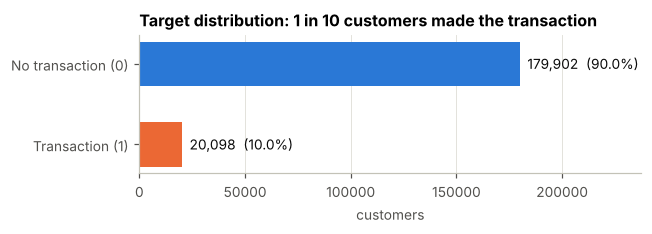

In [8]:
counts = pd.Series(y_all).value_counts().sort_index()
target_table = pd.DataFrame({'customers': counts.values, 'share %': (100 * counts / counts.sum()).round(2).values},
                            index=[CLASS_LABEL[0], CLASS_LABEL[1]])
display(target_table)
print(f'Imbalance ratio: {counts[0] / counts[1]:.2f} : 1')
print(f'Accuracy of a model that always predicts "no transaction": {counts[0] / counts.sum():.2%}')

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh([CLASS_LABEL[1], CLASS_LABEL[0]], [counts[1], counts[0]], color=[ORANGE, BLUE], height=0.55)
for i, v in enumerate([counts[1], counts[0]]):
    ax.text(v, i, f'  {v:,}  ({v / counts.sum():.1%})', va='center', color=INK)
ax.set_xlim(0, counts[0] * 1.32); ax.set_xlabel('customers'); ax.grid(axis='y', visible=False)
ax.set_title('Target distribution: 1 in 10 customers made the transaction')
plt.tight_layout(); plt.show()

**Findings.** Only 20,098 of the 200,000 customers (10.05 %) made the transaction, an imbalance of 8.95 : 1. A model that always says "no transaction" is already 89.95 % accurate, so **accuracy is not a useful metric here**. Models are compared on ROC-AUC (ranking quality) and PR-AUC, and the decision threshold is chosen as a separate step. The stratified split keeps exactly the same 10.05 % rate in the training and test sets.

### 3.2 Descriptive statistics of the 200 features (all 200,000 rows)

In [9]:
desc = X_all.describe().T
desc['skew'] = X_all.skew()
desc['kurtosis'] = X_all.kurt()
desc['n_unique'] = X_all.nunique()
print('First 8 features:')
display(desc.head(8).round(3))
print('Summary of the per-feature statistics across all 200 features:')
display(desc[['mean', 'std', 'min', 'max', 'skew', 'kurtosis', 'n_unique']].describe().round(3))

First 8 features:


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,n_unique
var_0,200000.0,10.680,3.040,0.408,8.454,10.525,12.758,20.315,0.236,-0.274,94672
var_1,200000.0,-1.628,4.050,-15.043,-4.740,-1.608,1.359,10.377,0.053,-0.607,108932
var_2,200000.0,10.715,2.641,2.117,8.722,10.580,12.517,19.353,0.260,-0.337,86555
var_3,200000.0,6.797,2.043,-0.040,5.254,6.825,8.324,13.188,-0.004,-0.603,74597
var_4,200000.0,11.078,1.623,5.075,9.883,11.108,12.261,16.671,-0.048,-0.535,63515
var_5,200000.0,-5.065,7.863,-32.563,-11.200,-4.833,0.925,17.252,-0.002,-0.669,141029
var_6,200000.0,5.409,0.867,2.347,4.768,5.385,6.003,8.448,0.149,-0.384,38599
var_7,200000.0,16.546,3.418,5.350,13.944,16.457,19.103,27.692,0.085,-0.671,103063


Summary of the per-feature statistics across all 200 features:


,mean,std,min,max,skew,kurtosis,n_unique
count,200.000,200.000,200.000,200.000,200.000,200.000,200.000
mean,6.767,4.495,-8.493,21.921,0.012,-0.498,97906.720
std,7.847,3.460,15.150,13.889,0.105,0.165,43599.732
min,-16.548,0.007,-90.253,1.572,-0.340,-0.812,451.000
25%,0.956,1.699,-16.349,12.687,-0.055,-0.633,64400.000
50%,6.583,3.945,-5.473,18.456,0.017,-0.505,108872.500
75%,12.360,6.347,2.152,27.768,0.082,-0.351,133935.250
max,24.521,21.405,13.729,74.032,0.267,-0.014,169968.000


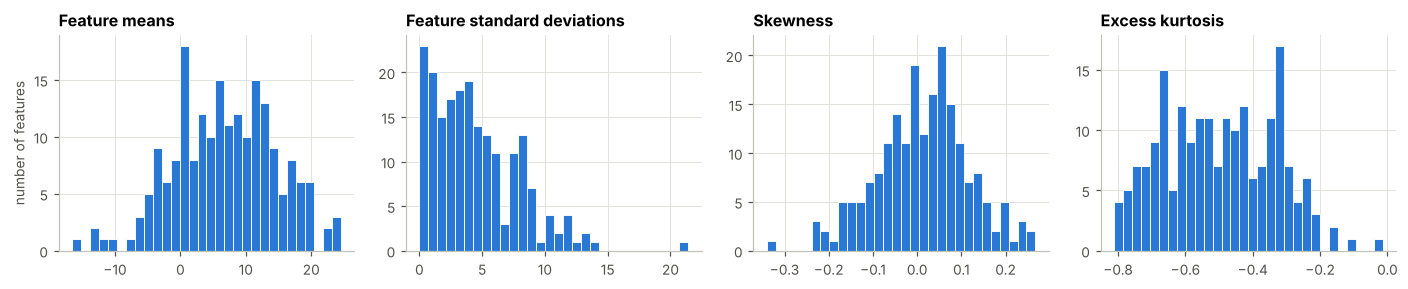

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.7))
for ax, col, title in zip(axes, ['mean', 'std', 'skew', 'kurtosis'],
                          ['Feature means', 'Feature standard deviations', 'Skewness', 'Excess kurtosis']):
    ax.hist(desc[col], bins=30, color=BLUE, edgecolor='white', linewidth=0.6)
    ax.set_title(title)
axes[0].set_ylabel('number of features')
plt.tight_layout(); plt.show()

**Findings.**
* The features are on very different scales. Means range from −16.5 to 24.5 and standard deviations from 0.007 (`var_68`) to 21.4, so distance-based and linear models need standardisation. Tree models do not.
* Every distribution is close to symmetric (skewness between −0.34 and 0.27) and slightly flatter than a normal curve: excess kurtosis is negative for all 200 features (−0.81 to −0.01). There are no long tails, so no log or power transforms are needed.
* The number of distinct values ranges from 451 (`var_68`) to 169,968. Section 3.7 looks at this in more detail.

### 3.3 Relationship of each feature with the target (training set)
Each feature is checked on its own with three measures: its correlation with the target, its univariate ROC-AUC (how well the feature alone ranks transacting customers, where 0.5 means no signal), and a Kolmogorov–Smirnov test of whether the feature's distribution differs between the two classes. The KS test uses a Bonferroni correction because 200 tests are run.

In [11]:
pos, neg = Xtr[y_train == 1], Xtr[y_train == 0]
rows = []
for j, f in enumerate(features):
    auc = roc_auc_score(y_train, Xtr[:, j])
    ks = stats.ks_2samp(pos[:, j], neg[:, j])
    rows.append({'feature': f, 'corr_with_target': np.corrcoef(Xtr[:, j], y_train)[0, 1],
                 'univariate_auc': max(auc, 1 - auc), 'higher_value_means': 'more likely' if auc >= 0.5 else 'less likely',
                 'mean_class0': neg[:, j].mean(), 'mean_class1': pos[:, j].mean(),
                 'ks_stat': ks.statistic, 'ks_pvalue': ks.pvalue})
ft = pd.DataFrame(rows).set_index('feature').sort_values('univariate_auc', ascending=False)
ALPHA = 0.05 / len(features)
ft['significant'] = ft['ks_pvalue'] < ALPHA
weak_features = ft.index[~ft['significant']].tolist()

print(f'Features whose distribution differs between the classes (KS, Bonferroni alpha = {ALPHA:.1e}): '
      f'{ft.significant.sum()} of {len(ft)}')
print(f'Largest |correlation| with target: {ft.corr_with_target.abs().max():.3f}')
print(f'Univariate AUC: best {ft.univariate_auc.max():.3f} ({ft.index[0]}), median {ft.univariate_auc.median():.3f}, '
      f'worst {ft.univariate_auc.min():.3f} ({ft.index[-1]})')
print('\nTop 10 features:')
display(ft.head(10).round(4))
print('Weakest 5 features:')
display(ft.tail(5).round(4))

Features whose distribution differs between the classes (KS, Bonferroni alpha = 2.5e-04): 155 of 200
Largest |correlation| with target: 0.082
Univariate AUC: best 0.568 (var_81), median 0.524, worst 0.500 (var_30)

Top 10 features:


,corr_with_target,univariate_auc,higher_value_means,mean_class0,mean_class1,ks_stat,ks_pvalue,significant
feature,,,,,,,,
var_81,-0.0818,0.5681,less likely,14.781700,14.154800,0.1208,0.0,True
var_139,-0.0770,0.5680,less likely,7.963000,5.994800,0.1205,0.0,True
var_6,0.0676,0.5611,more likely,5.391800,5.587000,0.1031,0.0,True
var_12,-0.0699,0.5597,less likely,14.028100,13.983900,0.0924,0.0,True
var_110,0.0656,0.5575,more likely,5.434800,6.269400,0.0970,0.0,True
var_76,-0.0631,0.5560,less likely,6.219400,4.552300,0.0900,0.0,True
var_146,-0.0635,0.5553,less likely,10.395300,9.863400,0.0876,0.0,True
var_53,0.0631,0.5545,more likely,5.992100,6.152500,0.0792,0.0,True
var_26,0.0633,0.5538,more likely,-4.177800,-2.931400,0.0861,0.0,True


Weakest 5 features:


,corr_with_target,univariate_auc,higher_value_means,mean_class0,mean_class1,ks_stat,ks_pvalue,significant
feature,,,,,,,,
var_27,-0.0009,0.5008,less likely,-1.1419,-1.1467,0.0055,0.7644,False
var_41,0.0006,0.5005,more likely,9.2964,9.3073,0.0058,0.7161,False
var_103,-0.0000,0.5002,less likely,1.5682,1.5682,0.0060,0.6789,False
var_185,-0.0001,0.5001,more likely,-3.9971,-3.9994,0.0045,0.9269,False
var_30,-0.0001,0.5000,more likely,-7.6843,-7.6870,0.0055,0.7645,False


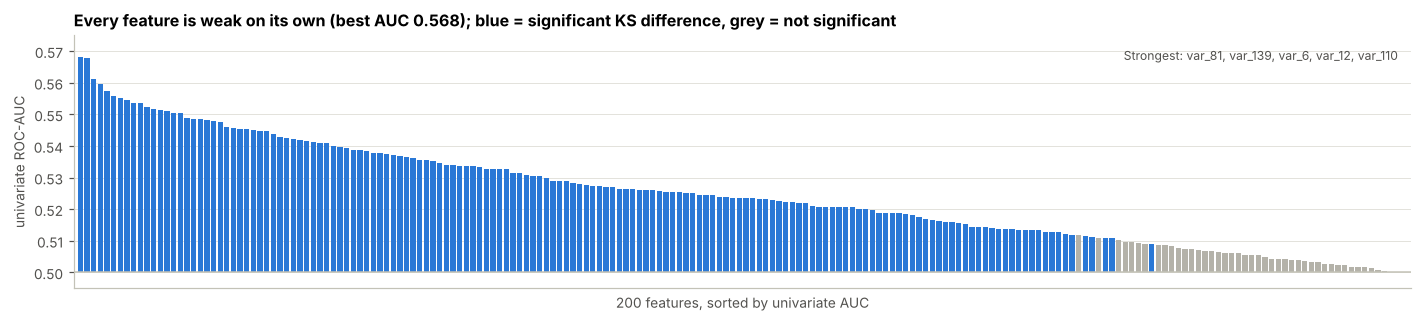

In [12]:
fig, ax = plt.subplots(figsize=(13, 3))
order = ft.sort_values('univariate_auc', ascending=False)
colors = [BLUE if s else GREY for s in order['significant']]
ax.bar(range(len(order)), order['univariate_auc'] - 0.5, bottom=0.5, color=colors, width=0.8)
ax.axhline(0.5, color='#c3c2b7', linewidth=1)
ax.text(0.99, 0.95, 'Strongest: ' + ', '.join(order.index[:5]), transform=ax.transAxes, ha='right', va='top',
        fontsize=8, color='#52514e')
ax.set_xlim(-1, len(order)); ax.set_xticks([]); ax.set_ylim(0.495, 0.575)
ax.set_xlabel('200 features, sorted by univariate AUC'); ax.set_ylabel('univariate ROC-AUC')
ax.set_title(f'Every feature is weak on its own (best AUC {order.univariate_auc.max():.3f}); '
             'blue = significant KS difference, grey = not significant')
plt.tight_layout(); plt.show()

**Findings.**
* **The signal is spread thinly across many features.** 155 of the 200 features differ significantly between the classes. However, even the best single feature (`var_81`) only reaches AUC 0.568, and no feature has a correlation above 0.082 with the target.
* The strongest features are `var_81`, `var_139`, `var_6`, `var_12` and `var_110`. *Lower* values of `var_81`, `var_139` and `var_12` make a transaction more likely, while *higher* values of `var_6` and `var_110` make it more likely.
* 45 features (e.g. `var_30`, `var_185`, `var_103`, `var_41`, `var_27`) show no significant difference on their own. Section 5.7 tests whether dropping them helps.
* No single feature is decisive, so a good model has to **add up many small pieces of evidence**.

### 3.4 Distributions by class: the six strongest and the two weakest features

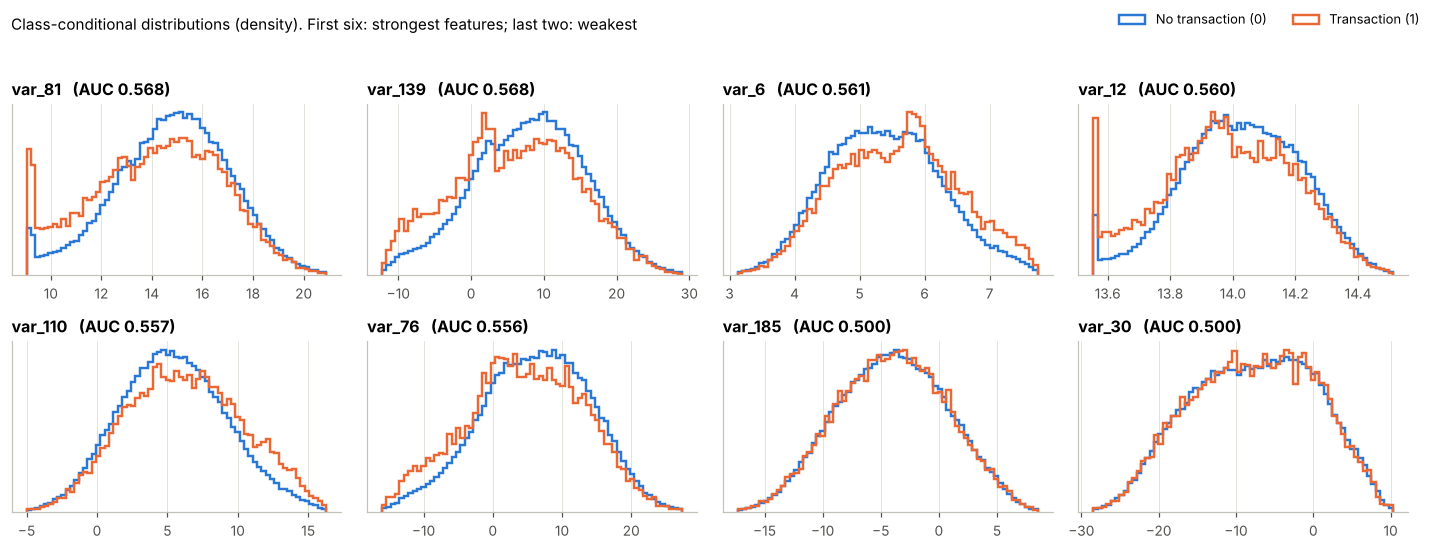

In [13]:
show = list(ft.index[:6]) + list(ft.index[-2:])
fig, axes = plt.subplots(2, 4, figsize=(13, 5))
for ax, f in zip(axes.ravel(), show):
    j = features.index(f)
    lo, hi = np.percentile(Xtr[:, j], [0.1, 99.9])
    bins = np.linspace(lo, hi, 70)
    for cls in [0, 1]:
        ax.hist(Xtr[y_train == cls, j], bins=bins, density=True, histtype='step', linewidth=1.6,
                color=CLASS_COLOR[cls], label=CLASS_LABEL[cls])
    ax.set_title(f'{f}   (AUC {ft.loc[f, "univariate_auc"]:.3f})'); ax.set_yticks([])
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle('Class-conditional distributions (density). First six: strongest features; last two: weakest',
             x=0.01, ha='left', fontsize=10)
plt.tight_layout(rect=(0, 0, 1, 0.95))
fig.legend(handles, labels, loc='upper right', ncol=2, fontsize=8.5)
plt.show()

In [14]:
# Where is the signal? Transaction rate in the extreme 1 % tails of the six strongest features (training set)
tails = []
for f in ft.index[:6]:
    x = X_train_df[f].to_numpy()
    low, high = x <= np.percentile(x, 1), x >= np.percentile(x, 99)
    tails.append({'feature': f, 'rate in lowest 1 % (%)': 100 * y_train[low].mean(),
                  'rate in highest 1 % (%)': 100 * y_train[high].mean(), 'overall rate (%)': 100 * y_train.mean()})
display(pd.DataFrame(tails).set_index('feature').round(1))

vc12 = X_train_df['var_12'].astype('float64').round(4).value_counts()
p1 = np.percentile(X_train_df['var_12'], 1)
print(f'var_12: its 3 most frequent values {vc12.index[:3].tolist()} ({vc12.iloc[:3].sum()} customers) all lie below '
      f'its 1st percentile ({p1:.4f}), i.e. customers pile up at the bottom of its range')

,rate in lowest 1 % (%),rate in highest 1 % (%),overall rate (%)
feature,,,
var_81,22.8,8.6,10.0
var_139,21.8,7.8,10.0
var_6,7.8,19.8,10.0
var_12,24.0,8.7,10.0
var_110,8.2,19.6,10.0
var_76,20.6,9.1,10.0


var_12: its 3 most frequent values [13.5545, 13.5547, 13.5544] (409 customers) all lie below its 1st percentile (13.5553), i.e. customers pile up at the bottom of its range


**Findings.** In the strong features the two classes do not differ by a shift of the whole distribution. The difference is concentrated **in one tail**. Customers in the lowest 1 % of `var_81`, `var_139` or `var_12` transact 22–24 % of the time, and customers in the highest 1 % of `var_6` or `var_110` about 20 % of the time, against 10 % overall. In the opposite tail the rate drops below average. `var_12` also has customers piled up at the bottom of its range (its three most frequent values all lie there), which is where its signal sits. The two weakest features have identical distributions in both classes.

### 3.5 Shape of the relationship: transaction rate across each feature's range
Each feature is cut into 20 equal-count bins and the transaction rate is computed in each bin. If the relationship were monotonic, the binned rate would rank customers about as well as the raw value. Features where the binned rate gives a clearly higher AUC would have a non-monotonic shape (bumps or U-shapes). To avoid rewarding noise, the bin rates are estimated on one half of the training set and scored on the other half, and then the halves are swapped (out-of-sample AUC).

Features where out-of-sample binning raises AUC by more than 0.005 (non-monotonic shape): 0 of 200; binning lowers AUC for 173 features


,univariate_auc,binned_auc_gain
feature,,
var_9,0.5370,0.0042
var_101,0.5089,0.0034
var_177,0.5328,0.0033
var_123,0.5341,0.0024
var_80,0.5477,0.0023
var_13,0.5487,0.0019


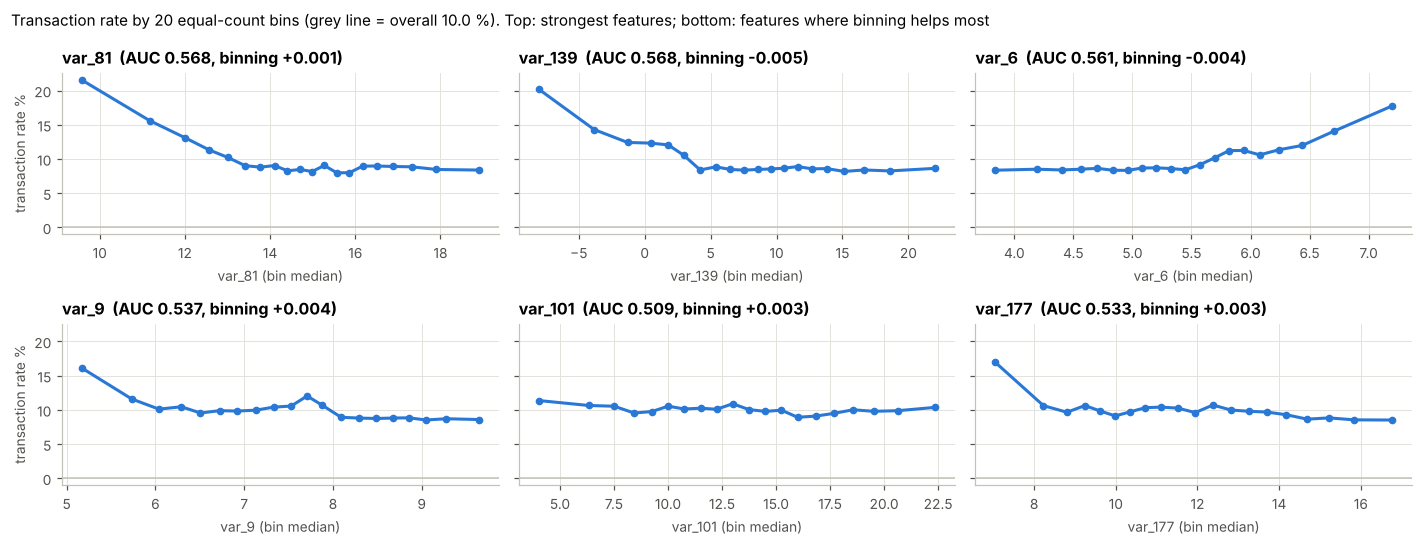

In [15]:
def binned_rate(x, y, q=20):
    edges = np.unique(np.quantile(x, np.linspace(0, 1, q + 1)))
    idx = np.clip(np.searchsorted(edges, x, side='right') - 1, 0, len(edges) - 2)
    n = np.bincount(idx, minlength=len(edges) - 1)
    rate = np.bincount(idx, weights=y, minlength=len(edges) - 1) / np.maximum(n, 1)
    return idx, rate

half = np.random.default_rng(SEED).random(len(y_train)) < 0.5

def out_of_sample_binned_auc(x, y, q=20):
    encoded = np.empty(len(y))
    for fit_part in [half, ~half]:
        edges = np.unique(np.quantile(x[fit_part], np.linspace(0, 1, q + 1)))
        nb = len(edges) - 1
        idx_fit = np.clip(np.searchsorted(edges, x[fit_part], side='right') - 1, 0, nb - 1)
        rate = np.bincount(idx_fit, weights=y[fit_part], minlength=nb) / np.maximum(np.bincount(idx_fit, minlength=nb), 1)
        idx_other = np.clip(np.searchsorted(edges, x[~fit_part], side='right') - 1, 0, nb - 1)
        encoded[~fit_part] = rate[idx_other]
    return roc_auc_score(y, encoded)

ft['binned_auc_gain'] = pd.Series({f: out_of_sample_binned_auc(Xtr[:, j], y_train) - ft.loc[f, 'univariate_auc']
                                   for j, f in enumerate(features)})
print(f'Features where out-of-sample binning raises AUC by more than 0.005 (non-monotonic shape): '
      f'{(ft.binned_auc_gain > 0.005).sum()} of 200; binning lowers AUC for {(ft.binned_auc_gain < 0).sum()} features')
display(ft.sort_values('binned_auc_gain', ascending=False)[['univariate_auc', 'binned_auc_gain']].head(6).round(4))

show = list(ft.index[:3]) + [f for f in ft.sort_values('binned_auc_gain', ascending=False).index if f not in ft.index[:3]][:3]
base_rate = y_train.mean()
fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharey=True)
for ax, f in zip(axes.ravel(), show):
    j = features.index(f)
    idx, rate = binned_rate(Xtr[:, j], y_train)
    centres = [np.median(Xtr[idx == b, j]) for b in range(len(rate))]
    ax.axhline(base_rate, color='#c3c2b7', linewidth=1)
    ax.plot(centres, rate * 100, marker='o', markersize=4, color=BLUE)
    ax.set_title(f'{f}  (AUC {ft.loc[f, "univariate_auc"]:.3f}, binning {ft.loc[f, "binned_auc_gain"]:+.3f})')
    ax.set_xlabel(f'{f} (bin median)')
for ax in axes[:, 0]:
    ax.set_ylabel('transaction rate %')
fig.suptitle(f'Transaction rate by 20 equal-count bins (grey line = overall {100 * base_rate:.1f} %). '
             'Top: strongest features; bottom: features where binning helps most',
             x=0.01, ha='left', fontsize=10)
plt.tight_layout(); plt.show()

**Findings.** No feature has a clearly non-monotonic shape. Tested out-of-sample, binning never raises the AUC by more than 0.005, and it lowers the AUC for 173 of the 200 features. The relationships are **monotonic but strongly non-linear**: the transaction rate is flat at about 8–9 % across most of the range and changes steeply in one tail only. For `var_81` the rate climbs from about 9 % to over 20 % in the lowest bins. For `var_6` it climbs from about 8.5 % to about 18 % in the highest bins. A linear model gives every unit of a feature the same weight and cannot represent these "flat-then-steep" curves. Models that learn a separate curve for each feature (Naive Bayes, a GAM, boosted stumps) should do better.

### 3.6 Correlation between features, multicollinearity and dimensionality
If the features were truly independent, the sample correlation of each pair would be pure noise with a standard deviation of about 1/√n.

19,900 feature pairs: max |r| = 0.0098, mean |r| = 0.0020
Pairs with |r| > 1.96/sqrt(n) = 0.0044: 8.0% (about 5 % expected for independent features)


Within class 0 (training set, n = 143,922): max |r| = 0.0099, noise level 1.96/sqrt(n) = 0.0052
Within class 1 (training set, n = 16,078): max |r| = 0.0317, noise level 1.96/sqrt(n) = 0.0155
Largest |r| expected by pure chance among 19,900 pairs: about 0.0117 in class 0 and 0.0351 in class 1


Training set: pairs beyond the noise band 7.3%; after removing the part explained by the target (rho_i x rho_j) 4.9%; corr(r, rho_i x rho_j) = 0.40
Variance inflation factor: min 1.0008, max 1.0021


PCA: first component explains 0.61%; components needed for 90 % variance: 179 of 200


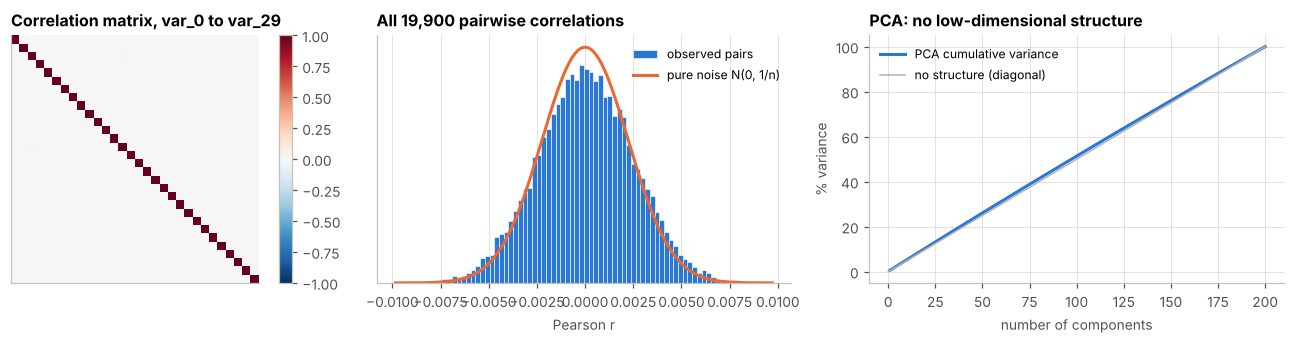

In [16]:
corr = np.corrcoef(X_all.to_numpy(np.float64), rowvar=False)
iu = np.triu_indices_from(corr, k=1)
r = corr[iu]
noise_sd = 1 / np.sqrt(len(X_all))
print(f'{len(r):,} feature pairs: max |r| = {np.abs(r).max():.4f}, mean |r| = {np.abs(r).mean():.4f}')
print(f'Pairs with |r| > 1.96/sqrt(n) = {1.96 * noise_sd:.4f}: {np.mean(np.abs(r) > 1.96 * noise_sd):.1%} '
      f'(about 5 % expected for independent features)')
for cls in [0, 1]:
    c = np.corrcoef(Xtr[y_train == cls].astype(np.float64), rowvar=False)[iu]
    print(f'Within class {cls} (training set, n = {(y_train == cls).sum():,}): max |r| = {np.abs(c).max():.4f}, '
          f'noise level 1.96/sqrt(n) = {1.96 / np.sqrt((y_train == cls).sum()):.4f}')
expected_max = np.sqrt(2 * np.log(len(r)))     # largest |z| expected by chance among 19,900 pairs (about 4.45 sd)
print(f'Largest |r| expected by pure chance among {len(r):,} pairs: about {expected_max / np.sqrt((y_train == 0).sum()):.4f} '
      f'in class 0 and {expected_max / np.sqrt((y_train == 1).sum()):.4f} in class 1')

# Two features that both shift with the target become slightly correlated in the pooled data (r_ij ~ rho_i * rho_j)
r_tr = np.corrcoef(Xtr.astype(np.float64), rowvar=False)[iu]
rho = ft.loc[features, 'corr_with_target'].to_numpy()
induced = np.outer(rho, rho)[iu]
band = 1.96 / np.sqrt(len(y_train))
print(f'Training set: pairs beyond the noise band {np.mean(np.abs(r_tr) > band):.1%}; after removing the part explained by the '
      f'target (rho_i x rho_j) {np.mean(np.abs(r_tr - induced) > band):.1%}; corr(r, rho_i x rho_j) = {np.corrcoef(r_tr, induced)[0, 1]:.2f}')
vif = np.diag(np.linalg.inv(corr))
print(f'Variance inflation factor: min {vif.min():.4f}, max {vif.max():.4f}')

Z = StandardScaler().fit_transform(X_all)
pca = PCA().fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_)
print(f'PCA: first component explains {pca.explained_variance_ratio_[0]:.2%}; components needed for 90 % variance: '
      f'{np.searchsorted(cum, 0.90) + 1} of 200')
del Z

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
sub = corr[:30, :30]
im = axes[0].imshow(sub, cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].set_title('Correlation matrix, var_0 to var_29'); axes[0].set_xticks([]); axes[0].set_yticks([]); axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].hist(r, bins=80, density=True, color=BLUE, edgecolor='white', linewidth=0.4, label='observed pairs')
grid = np.linspace(r.min(), r.max(), 200)
axes[1].plot(grid, stats.norm.pdf(grid, 0, noise_sd), color=ORANGE, label='pure noise N(0, 1/n)')
axes[1].set_title('All 19,900 pairwise correlations'); axes[1].set_xlabel('Pearson r'); axes[1].set_yticks([]); axes[1].legend(fontsize=8)
axes[2].plot(np.arange(1, 201), cum * 100, color=BLUE, label='PCA cumulative variance')
axes[2].plot([0, 200], [0, 100], color=GREY, linewidth=1, label='no structure (diagonal)')
axes[2].set_title('PCA: no low-dimensional structure'); axes[2].set_xlabel('number of components'); axes[2].set_ylabel('% variance')
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Findings.**
* **The features are practically uncorrelated.** The largest of the 19,900 pairwise correlations is 0.0098. All variance inflation factors are between 1.0008 and 1.0021. PCA finds no structure: the first component explains 0.61 % of the variance and 179 of 200 components are needed for 90 %. Multicollinearity is therefore not an issue, and PCA or any other dimensionality reduction would only lose information.
* Slightly more pairs fall outside the pure-noise band than the 5 % expected (8.0 % on all data). The target explains this: two features that both shift with the class become very slightly correlated when the classes are pooled. After removing that part (ρᵢ × ρⱼ), the share in the training set drops from 7.3 % to 4.9 %, which is exactly what independent features give. Within each class, the largest correlations (0.0099 and 0.0317) are below what chance alone produces across 19,900 pairs.
* **Conclusion: within each class, the features are independent of each other.** This is the most important structural fact in the data. It means the Naive Bayes assumption holds, interactions between features carry almost no information, and the log-odds of a transaction is close to a *sum of one function per feature*.

### 3.7 Unique values and value frequency
Values are recorded to 4 decimal places, so the same exact value can appear for several customers. This section checks how often each value repeats and whether customers with a value that nobody else has ("unique" values) behave differently.

In [17]:
nunq = X_all.nunique().sort_values()
print('Unique values per feature:')
print(nunq.describe().round(0).to_string())
print('\nFeatures with the fewest unique values:', nunq.head(5).to_dict())
print(f'var_68 range: {X_all["var_68"].min():.4f} to {X_all["var_68"].max():.4f} '
      f'(std {X_all["var_68"].std():.4f}), so its {nunq["var_68"]} values are tightly packed')

# Value counts inside the training set: for each cell, how many training customers share that exact value?
keys_tr = np.rint(Xtr.astype(np.float64) * 1e4).astype(np.int64)
cnt_tr = np.empty(keys_tr.shape, dtype=np.int32)
for j in range(keys_tr.shape[1]):
    v, c = np.unique(keys_tr[:, j], return_counts=True)
    cnt_tr[:, j] = c[np.searchsorted(v, keys_tr[:, j])]
is_unique = cnt_tr == 1
print(f'\nShare of training values that are unique within their feature: {is_unique.mean():.1%} '
      f'(range across features {is_unique.mean(0).min():.1%} to {is_unique.mean(0).max():.1%})')

freq = pd.DataFrame({
    'share_unique': is_unique.mean(0),
    'rate_if_unique': [y_train[is_unique[:, j]].mean() if is_unique[:, j].any() else np.nan for j in range(200)],
    'rate_if_repeated': [y_train[~is_unique[:, j]].mean() for j in range(200)],
}, index=features)
freq['difference_pp'] = 100 * (freq.rate_if_unique - freq.rate_if_repeated)
print(f'Features where customers with a unique value transact more often than those with a repeated value: '
      f'{(freq.difference_pp > 0).sum()} of {freq.difference_pp.notna().sum()}')
print(f'Pooled over all cells: transaction rate {y_train[np.where(is_unique)[0]].mean():.2%} for unique values vs '
      f'{y_train[np.where(~is_unique)[0]].mean():.2%} for repeated values')
display(freq.loc[ft.index[:8]].round(4))

Unique values per feature:
count       200.0
mean      97907.0
std       43600.0
min         451.0
25%       64400.0
50%      108872.0
75%      133935.0
max      169968.0

Features with the fewest unique values: {'var_68': 451, 'var_91': 7962, 'var_108': 8525, 'var_103': 9376, 'var_12': 9561}
var_68 range: 4.9938 to 5.0469 (std 0.0072), so its 451 values are tightly packed



Share of training values that are unique within their feature: 32.4% (range across features 0.0% to 76.6%)


Features where customers with a unique value transact more often than those with a repeated value: 166 of 200


Pooled over all cells: transaction rate 10.18% for unique values vs 9.99% for repeated values


,share_unique,rate_if_unique,rate_if_repeated,difference_pp
feature,,,,
var_81,0.1857,0.1135,0.0975,1.6018
var_139,0.5300,0.1027,0.0980,0.4724
var_6,0.0446,0.1154,0.0998,1.5632
var_12,0.0033,0.0979,0.1005,-0.2568
var_110,0.3297,0.1067,0.0974,0.9299
var_76,0.5443,0.1029,0.0976,0.5303
var_146,0.2109,0.1092,0.0982,1.1009
var_53,0.0313,0.1186,0.0999,1.8648


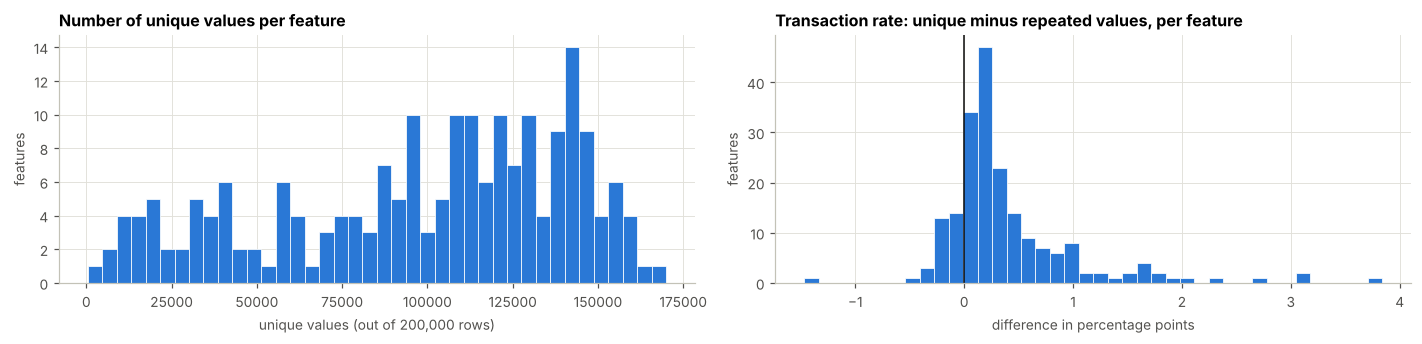

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
axes[0].hist(nunq.values, bins=40, color=BLUE, edgecolor='white', linewidth=0.5)
axes[0].set_title('Number of unique values per feature'); axes[0].set_xlabel('unique values (out of 200,000 rows)')
axes[0].set_ylabel('features')
axes[1].hist(freq.difference_pp.dropna(), bins=40, color=BLUE, edgecolor='white', linewidth=0.5)
axes[1].axvline(0, color=INK, linewidth=1)
axes[1].set_title('Transaction rate: unique minus repeated values, per feature')
axes[1].set_xlabel('difference in percentage points'); axes[1].set_ylabel('features')
plt.tight_layout(); plt.show()
del keys_tr, cnt_tr, is_unique

**Findings.**
* Most features have tens of thousands of distinct values (median about 109,000), but a few are coarse. `var_68` has only 451 distinct values, packed between 4.9938 and 5.0469, so it behaves almost like a categorical variable. `var_91`, `var_108`, `var_103` and `var_12` have fewer than 10,000 each.
* 32.4 % of all training values are unique within their feature. The share ranges from 0 % to 77 % depending on the feature.
* Customers whose value is unique transact slightly more often. This holds in 166 of 200 features, and pooled over all cells the rate is 10.18 % for unique values vs 9.99 % for repeated ones. For some strong features the gap reaches 1.5–1.9 percentage points (`var_81`, `var_6`, `var_53`).
* The effect is small, but it is systematic across features. **How often a value occurs carries information that the value alone does not.** This is the idea behind the frequency features in Sections 4.1 and 5.5.

### 3.8 Outliers

In [19]:
q1, q3 = np.percentile(Xtr, [25, 75], axis=0)
iqr = q3 - q1
outlier = (Xtr < q1 - 1.5 * iqr) | (Xtr > q3 + 1.5 * iqr)
has_outlier = outlier.any(axis=1)
z = np.abs((Xtr - Xtr.mean(0)) / Xtr.std(0))
print(f'IQR rule: {outlier.mean():.3%} of all values are outliers; {has_outlier.mean():.1%} of customers have at least one')
print(f'Features with any IQR outlier: {(outlier.sum(0) > 0).sum()} of 200; most affected: '
      f'{features[outlier.sum(0).argmax()]} ({outlier.mean(0).max():.2%} of its values)')
print(f'|z| > 3: {(z > 3).mean():.3%} of values; largest |z| = {z.max():.1f}')
print(f'Transaction rate: customers with an outlier {y_train[has_outlier].mean():.2%}, without {y_train[~has_outlier].mean():.2%}')
del outlier, z

IQR rule: 0.066% of all values are outliers; 12.5% of customers have at least one
Features with any IQR outlier: 189 of 200; most affected: var_179 (0.74% of its values)
|z| > 3: 0.028% of values; largest |z| = 4.5
Transaction rate: customers with an outlier 12.03%, without 9.77%


**Findings.** Outliers are rare and mild. Only 0.066 % of values fall outside the 1.5 × IQR fences, and the most extreme value is 4.5 standard deviations from its mean, which is unremarkable among 32 million values. They are spread over 189 features, so 12.5 % of customers have at least one. Those customers transact **more** often (12.03 % vs 9.77 %). The extreme values are the "steep tails" from Section 3.5, which carry the signal, so they are not errors.

**Decision:** Keep all outliers. Removing them would delete 12.5 % of the customers, including a disproportionate share of those who transact, and capping them would flatten the tails where the signal sits. Tree-based models are not sensitive to extreme values anyway.

### 3.9 Data analysis summary

| # | Finding | Evidence | Consequence for modelling |
|---|---|---|---|
| 1 | Clean data | 0 missing values, 0 duplicates; `ID_code` = row number | No imputation; drop `ID_code` |
| 2 | Imbalanced target | 10.05 % transact (8.95 : 1) | ROC-AUC / PR-AUC, stratified splits, threshold chosen separately |
| 3 | Weak signal spread over many features | Best single-feature AUC 0.568; 155 of 200 features significant | The model must combine all features |
| 4 | Monotonic but non-linear effects | Flat-then-steep curves; binning never helps by more than 0.005 | Flexible per-feature curves instead of linear terms |
| 5 | Independent features | Max \|r\| 0.0098, VIF ≤ 1.002, flat PCA, within-class correlations at noise level | Naive Bayes / additive models, very shallow trees, no PCA |
| 6 | Value frequency carries signal | Unique values: 10.18 % vs 9.99 % transaction rate; higher in 166 of 200 features | Add value-count (frequency) features |
| 7 | Mild, informative outliers | 0.066 % of values; customers with outliers transact more | Keep them; no capping |
| 8 | Very different scales | Std from 0.007 to 21.4 | Standardise for linear, KNN and MLP models |

## 4. Data preparation and feature engineering

| Step | Decision | Reason |
|---|---|---|
| `ID_code` | Dropped | Row number with no information (AUC 0.502) |
| Missing values / duplicates | No action needed | None present |
| Data type | float32 | Halves memory with no loss at 4 decimals |
| Outliers | Kept | Rare, mild and informative (3.8) |
| Scaling | `StandardScaler` inside the pipelines of LR, KNN, MLP and the GAM | Only scale-sensitive models need it; fitted inside each CV fold, so nothing leaks |
| Feature selection | None by default (tested in 5.7) | Even "weak" features add a little evidence |
| Dimensionality reduction | None | PCA finds no structure (3.6) |
| Class imbalance | Tested in 5.3 | — |
| New features | Value-count (frequency) features, tested in 5.5 | Finding 6 in 3.9 |

### 4.1 Frequency (value-count) encoder
For every feature, the encoder adds a second column: how many customers in the **training data** have exactly the same value. It is written as a scikit-learn transformer so it sits inside the model pipeline and is re-fitted inside every cross-validation fold. This means no information from validation or test rows leaks into the counts.

* During training (`fit_transform`), each row's count includes the row itself, so a unique value has count 1.
* For new customers (`transform`), the count is the training count + 1, which adds the new customer. A value never seen in training then gets count 1, the same meaning as a unique value during training.

In [20]:
class ValueCountEncoder(BaseEstimator, TransformerMixin):
    # Appends, for each input column, the number of training rows that share exactly the same value.
    def __init__(self, decimals=4):
        self.decimals = decimals

    def _keys(self, X):
        return np.rint(np.asarray(X, dtype=np.float64) * 10 ** self.decimals).astype(np.int64)

    def fit(self, X, y=None):
        K = self._keys(X)
        self.values_, self.counts_ = [], []
        for j in range(K.shape[1]):
            v, c = np.unique(K[:, j], return_counts=True)
            self.values_.append(v.astype(np.int32))      # 4-decimal values * 1e4 fit easily in int32
            self.counts_.append(c.astype(np.uint16))     # largest count in this data is about 1,100 (uint16 holds 65,535)
        return self

    def _lookup(self, K):
        out = np.zeros(K.shape, dtype=np.float32)
        for j in range(K.shape[1]):
            v, c = self.values_[j], self.counts_[j]
            pos = np.clip(np.searchsorted(v, K[:, j]), 0, len(v) - 1)
            out[:, j] = np.where(v[pos] == K[:, j], c[pos], 0)
        return out

    def fit_transform(self, X, y=None):          # training rows: count includes the row itself
        self.fit(X)
        return np.hstack([np.asarray(X, dtype=np.float32), self._lookup(self._keys(X))])

    def transform(self, X):                      # new rows: training count + the new row itself
        return np.hstack([np.asarray(X, dtype=np.float32), self._lookup(self._keys(X)) + 1])

# Small demonstration on one column
demo = np.array([[1.2345], [1.2345], [2.0], [3.5]])
enc_demo = ValueCountEncoder()
print('fit_transform on training rows:\n', enc_demo.fit_transform(demo))
print('transform on new rows [1.2345], [2.0], [9.9]:\n', enc_demo.transform(np.array([[1.2345], [2.0], [9.9]])))

# Consistency check on the real split: the share of 'count = 1' should be the same for training and new rows
enc_check = ValueCountEncoder()
F_tr = enc_check.fit_transform(Xtr); F_te = enc_check.transform(Xte)
print(f'\nShare of count = 1 cells: training rows {np.mean(F_tr[:, 200:] == 1):.4f}, test rows {np.mean(F_te[:, 200:] == 1):.4f}')
del F_tr, F_te, enc_check

fit_transform on training rows:
 [[1.2345 2.    ]
 [1.2345 2.    ]
 [2.     1.    ]
 [3.5    1.    ]]
transform on new rows [1.2345], [2.0], [9.9]:
 [[1.2345 3.    ]
 [2.     2.    ]
 [9.9    1.    ]]



Share of count = 1 cells: training rows 0.3241, test rows 0.3239


## 5. Modelling experiments (Task 2)
### 5.1 Evaluation design
* **Metric:** ROC-AUC is the main metric. It measures how well the model ranks transacting customers above non-transacting ones and does not depend on a threshold, and accuracy is useless at a 90 / 10 split. PR-AUC (average precision), log loss and threshold-based precision / recall / F1 are also reported.
* **Tuning:** Hyperparameters are chosen on an *inner* split of the training set (80 % / 20 %, seed 7), using early stopping for the boosting models.
* **Comparison:** Every model is then evaluated with **5-fold stratified cross-validation** on the 160,000 training rows, using the same folds for every model. For the hold-out score, the five fold models each predict the test set and their probabilities are averaged.
* The hold-out test set (40,000 rows) is only used for reporting.

In [21]:
FOLDS = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(Xtr, y_train))
Xa, Xv, ya, yv = train_test_split(Xtr, y_train, test_size=0.20, stratify=y_train, random_state=7)
print(f'Inner tuning split: {len(ya):,} fit rows / {len(yv):,} validation rows (same size as a CV fold)')

def lgbm(n_estimators=20000, learning_rate=0.1, **params):
    # LightGBM with the shared settings used in this notebook
    base = dict(subsample=0.4, subsample_freq=5, min_child_samples=80, metric='auc', random_state=SEED,
                n_jobs=N_JOBS, deterministic=True, force_col_wise=True, verbose=-1)
    base.update(params)
    return lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=learning_rate, **base)

def fit_early_stopping(model, Xa, ya, Xv, yv, patience=300):
    t = time.time()
    model.fit(Xa, ya, eval_set=[(Xv, yv)], callbacks=[lgb.early_stopping(patience, verbose=False)])
    return model.best_iteration_, model.best_score_['valid_0']['auc'], time.time() - t

Inner tuning split: 128,000 fit rows / 32,000 validation rows (same size as a CV fold)


### 5.2 Tuning LightGBM: how complex should each tree be?
Section 3 showed that the features are independent of each other and each carries a small amount of signal. If that is true, interactions between features add little, and **very small trees** (few leaves, few features per tree) should work best. The two settings that control this are tested on the inner split: `num_leaves` (tree size) and `colsample_bytree` (share of features each tree can use).

In [22]:
sweep = []
for nl in [2, 3, 4, 8, 16, 31]:
    it, auc, s = fit_early_stopping(lgbm(num_leaves=nl, colsample_bytree=0.05), Xa, ya, Xv, yv)
    sweep.append({'num_leaves': nl, 'colsample_bytree': 0.05, 'best_rounds': it, 'val_auc': auc, 'seconds': s})
    print(f'num_leaves={nl:<3d} colsample=0.05  rounds={it:<5d} val AUC={auc:.4f}  ({s:.0f}s)')
best_nl = int(pd.DataFrame(sweep).sort_values('val_auc').iloc[-1]['num_leaves'])
for cs in [0.02, 0.15, 0.5]:
    it, auc, s = fit_early_stopping(lgbm(num_leaves=best_nl, colsample_bytree=cs), Xa, ya, Xv, yv)
    sweep.append({'num_leaves': best_nl, 'colsample_bytree': cs, 'best_rounds': it, 'val_auc': auc, 'seconds': s})
    print(f'num_leaves={best_nl:<3d} colsample={cs:<5} rounds={it:<5d} val AUC={auc:.4f}  ({s:.0f}s)')
sweep = pd.DataFrame(sweep)
best = sweep.sort_values('val_auc').iloc[-1]
LGB_PARAMS = dict(num_leaves=int(best.num_leaves), colsample_bytree=float(best.colsample_bytree))
print('\nChosen:', LGB_PARAMS)

# Final number of rounds at a lower learning rate (0.05) for the tuned model
it, auc, s = fit_early_stopping(lgbm(learning_rate=0.05, **LGB_PARAMS), Xa, ya, Xv, yv)
LGB_ROUNDS = it
LGB_VAL_AUC_LR01 = float(best.val_auc)
print(f'learning_rate=0.05: rounds={it}, val AUC={auc:.4f} ({s:.0f}s)')

num_leaves=2   colsample=0.05  rounds=3871  val AUC=0.8987  (23s)


num_leaves=3   colsample=0.05  rounds=1781  val AUC=0.8955  (14s)


num_leaves=4   colsample=0.05  rounds=1933  val AUC=0.8953  (16s)


num_leaves=8   colsample=0.05  rounds=910   val AUC=0.8934  (12s)


num_leaves=16  colsample=0.05  rounds=676   val AUC=0.8889  (12s)


num_leaves=31  colsample=0.05  rounds=648   val AUC=0.8803  (12s)


num_leaves=2   colsample=0.02  rounds=3482  val AUC=0.8978  (20s)


num_leaves=2   colsample=0.15  rounds=3483  val AUC=0.8984  (25s)


num_leaves=2   colsample=0.5   rounds=2749  val AUC=0.8979  (31s)

Chosen: {'num_leaves': 2, 'colsample_bytree': 0.05}


learning_rate=0.05: rounds=6092, val AUC=0.8977 (33s)


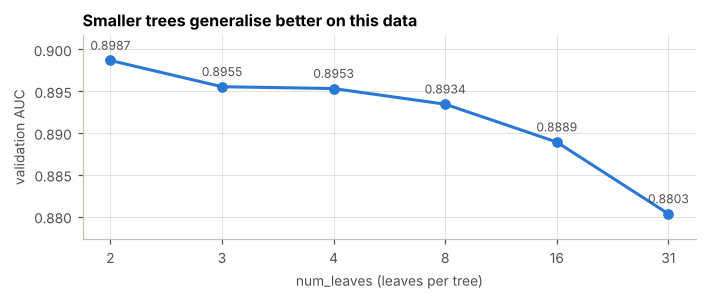

In [23]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
s1 = sweep[sweep.colsample_bytree == 0.05].sort_values('num_leaves')
ax.plot(s1.num_leaves.astype(str), s1.val_auc, marker='o', markersize=6, color=BLUE)
for _, row in s1.iterrows():
    ax.annotate(f'{row.val_auc:.4f}', (str(int(row.num_leaves)), row.val_auc), xytext=(0, 7),
                textcoords='offset points', ha='center', fontsize=8, color='#52514e')
ax.set_xlabel('num_leaves (leaves per tree)'); ax.set_ylabel('validation AUC')
ax.set_title('Smaller trees generalise better on this data')
ax.set_ylim(s1.val_auc.min() - 0.003, s1.val_auc.max() + 0.003)
plt.tight_layout(); plt.show()

**Findings.** The smallest possible trees win. With **2 leaves per tree** (a single split, called a "stump"), validation AUC is 0.8987. It falls steadily as trees grow, down to 0.8803 at LightGBM's default of 31 leaves. A model made only of stumps cannot learn any interaction between features: it is a sum of one step-function per feature, i.e. an additive model, which confirms Section 3.6. Using a small share of features per tree also works best (5 %, though 2–50 % all give 0.8978–0.8987), because it spreads the model's effort over all features. The tuned model is retrained at learning rate 0.05, where early stopping picks 6,092 rounds.

### 5.3 Handling the class imbalance
Four options are compared on the inner split for a linear model and for the tuned LightGBM: no re-balancing, class weights, SMOTE over-sampling and random under-sampling. The boosting models use early stopping on the validation part, so every option gets the same (slightly optimistic) treatment. The comparison looks at ranking quality (ROC-AUC, PR-AUC), at probability quality (log loss, Brier score), and at precision / recall at the default 0.5 threshold.

In [24]:
neg_pos_ratio = (ya == 0).sum() / (ya == 1).sum()

def resample(strategy):
    if strategy == 'SMOTE':
        return SMOTE(random_state=SEED).fit_resample(Xa, ya)
    if strategy == 'Random under-sampling':
        return RandomUnderSampler(random_state=SEED).fit_resample(Xa, ya)
    return Xa, ya

def scores(y, p):
    pred = (p >= 0.5).astype(int)
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p), 'log loss': log_loss(y, p),
            'Brier': brier_score_loss(y, p), 'precision@0.5': precision_score(y, pred, zero_division=0),
            'recall@0.5': recall_score(y, pred)}

imb = []
for strategy in ['None', 'Class weights', 'SMOTE', 'Random under-sampling']:
    Xs, ys = resample(strategy)
    lr_model = make_pipeline(StandardScaler(), LogisticRegression(
        max_iter=1000, class_weight='balanced' if strategy == 'Class weights' else None)).fit(Xs, ys)
    imb.append({'model': 'Logistic Regression', 'strategy': strategy, 'train rows': len(ys),
                **scores(yv, lr_model.predict_proba(Xv)[:, 1])})
    extra = {'scale_pos_weight': neg_pos_ratio} if strategy == 'Class weights' else {}
    m = lgbm(**LGB_PARAMS, **extra)
    fit_early_stopping(m, Xs, ys, Xv, yv)
    imb.append({'model': 'LightGBM (tuned)', 'strategy': strategy, 'train rows': len(ys),
                **scores(yv, m.predict_proba(Xv)[:, 1])})
    print(f'{strategy} done')
imb = pd.DataFrame(imb).set_index(['model', 'strategy'])
imb.round(4)

None done


Class weights done


SMOTE done


Random under-sampling done


,,train rows,ROC-AUC,PR-AUC,log loss,Brier,precision@0.5,recall@0.5
model,strategy,,,,,,,
Logistic Regression,None,128000,0.8603,0.5060,0.2317,0.0666,0.6859,0.2805
LightGBM (tuned),None,128000,0.8987,0.6103,0.2030,0.0583,0.7454,0.3759
Logistic Regression,Class weights,128000,0.8600,0.5049,0.4636,0.1516,0.2820,0.7727
LightGBM (tuned),Class weights,128000,0.8976,0.6059,0.3917,0.1233,0.3474,0.8007
Logistic Regression,SMOTE,230276,0.8597,0.5033,0.4538,0.1475,0.2886,0.7655
LightGBM (tuned),SMOTE,230276,0.7997,0.3777,0.3353,0.1024,0.3531,0.4686
Logistic Regression,Random under-sampling,25724,0.8588,0.5022,0.4648,0.1521,0.2793,0.7715
LightGBM (tuned),Random under-sampling,25724,0.8943,0.5972,0.4080,0.1291,0.3332,0.7976


**Findings.**
* **Re-balancing does not improve ranking.** With class weights, ROC-AUC barely moves (0.8603 → 0.8600 for LR, 0.8987 → 0.8976 for LightGBM). Under-sampling throws away 80 % of the data and loses some AUC (0.8943).
* **SMOTE is harmful here**: LightGBM's AUC drops to 0.7997. SMOTE creates synthetic customers by interpolating between real ones in 200-dimensional space, which narrows every feature's distribution for the positive class. The stump model then partly learns to recognise "synthetic" rather than "transacting" customers. Logistic regression mainly responds to the shift in class means, which interpolation preserves, so it is barely affected.
* All three methods **damage the probabilities**. LightGBM's log loss roughly doubles (0.20 → 0.34–0.41), because the model now believes about half of customers transact.
* What re-balancing *does* change is the trade-off at the 0.5 threshold. Recall rises from 0.38 to about 0.80, at the cost of precision. Moving the threshold gives the same trade-off without distorting the model.

**Decision:** Train on the original class distribution, use stratified folds, and choose the decision threshold separately (Section 7.1).

### 5.4 An additive model (GAM) built from splines + logistic regression
Section 3 found independent features, each with its own (sometimes non-monotonic) relationship to the target. Under those conditions the log-odds of a transaction is close to a **sum of one smooth function per feature**. That is a generalised additive model (GAM). It is built here by expanding each feature into cubic B-splines (`SplineTransformer`) and fitting a regularised logistic regression on top. A small grid of knots and regularisation strength is tested on the inner split.

In [25]:
def make_gam(n_knots=5, C=0.1):
    return make_pipeline(StandardScaler(), SplineTransformer(n_knots=n_knots, degree=3, knots='quantile'),
                         LogisticRegression(C=C, max_iter=3000))

gam_grid = []
for n_knots, C in [(5, 0.01), (5, 0.1), (5, 1.0), (8, 0.1)]:
    t = time.time()
    p = make_gam(n_knots, C).fit(Xa, ya).predict_proba(Xv)[:, 1]
    gam_grid.append({'n_knots': n_knots, 'C': C, 'val_auc': roc_auc_score(yv, p), 'seconds': time.time() - t})
    print(f'n_knots={n_knots} C={C:<5} val AUC={gam_grid[-1]["val_auc"]:.4f} ({gam_grid[-1]["seconds"]:.0f}s)')
gam_best = pd.DataFrame(gam_grid).sort_values('val_auc').iloc[-1]
GAM_PARAMS = dict(n_knots=int(gam_best.n_knots), C=float(gam_best.C))
print('Chosen:', GAM_PARAMS)

n_knots=5 C=0.01  val AUC=0.8809 (11s)


n_knots=5 C=0.1   val AUC=0.8952 (14s)


n_knots=5 C=1.0   val AUC=0.8955 (16s)


n_knots=8 C=0.1   val AUC=0.8956 (14s)
Chosen: {'n_knots': 8, 'C': 0.1}


**Findings.** The spline GAM reaches a validation AUC of 0.8956 (8 knots, C = 0.1). That is far above plain logistic regression (0.8603 in 5.3), even though the GAM is also a linear model in the end. The only difference is that each feature can now have a curved effect. Weak regularisation (C ≥ 0.1) is needed, and 5 or 8 knots make little difference.

### 5.5 Frequency features: does the value count add information?
Section 3.7 showed that customers whose value is unique within a feature have a slightly different transaction rate. Two ways of using the count are tested with LightGBM:

* **(a)** The 200 count columns are added as ordinary extra features (400 features, tuned settings).
* **(b)** Each feature may only interact with *its own* count (LightGBM `interaction_constraints`). The model is still additive across features, but each feature's effect can now depend on whether its value is common or rare.

**(c)** is a control: the same per-feature constraint without counts. It separates the effect of the constraint from the effect of the counts.

In [26]:
enc = ValueCountEncoder()
Fa, Fv = enc.fit_transform(Xa), enc.transform(Xv)
PAIRS = [[j, j + 200] for j in range(200)]          # feature j may only interact with its own count (column j + 200)
SINGLES = [[j] for j in range(200)]
CNT_PARAMS = dict(num_leaves=4, colsample_bytree=0.5, interaction_constraints=PAIRS)

freq_exp = [{'variant': 'Baseline: tuned LightGBM, 200 raw features (from 5.2)', 'val_auc': LGB_VAL_AUC_LR01, 'rounds': int(best.best_rounds)}]
for name, model, A, V in [
        ('(a) + 200 count features, unconstrained', lgbm(**LGB_PARAMS), Fa, Fv),
        ('(b) + count features, each feature paired only with its own count', lgbm(**CNT_PARAMS), Fa, Fv),
        ('(c) control: per-feature constraint, no counts', lgbm(num_leaves=4, colsample_bytree=0.5, interaction_constraints=SINGLES), Xa, Xv)]:
    it, auc, s = fit_early_stopping(model, A, ya, V, yv)
    freq_exp.append({'variant': name, 'val_auc': auc, 'rounds': it})
    print(f'{name:<70s} val AUC={auc:.4f}  rounds={it}  ({s:.0f}s)')
freq_exp = pd.DataFrame(freq_exp).set_index('variant')
CNT_ROUNDS = int(freq_exp.loc['(b) + count features, each feature paired only with its own count', 'rounds'])
freq_exp['gain_vs_baseline'] = freq_exp.val_auc - LGB_VAL_AUC_LR01
freq_exp.round(4)

(a) + 200 count features, unconstrained                                val AUC=0.8979  rounds=3596  (34s)


(b) + count features, each feature paired only with its own count      val AUC=0.9028  rounds=2206  (67s)


(c) control: per-feature constraint, no counts                         val AUC=0.8975  rounds=2000  (30s)


,val_auc,rounds,gain_vs_baseline
variant,,,
"Baseline: tuned LightGBM, 200 raw features (from 5.2)",0.8987,3871,0.0000
"(a) + 200 count features, unconstrained",0.8979,3596,-0.0008
"(b) + count features, each feature paired only with its own count",0.9028,2206,0.0042
"(c) control: per-feature constraint, no counts",0.8975,2000,-0.0012


**Findings.**
* Adding the counts as ordinary features **(a)** does nothing (−0.0008). On its own, the count of a value tells the model very little.
* Letting each feature interact with its own count **(b)** gives a clear gain of **+0.0042 AUC** (0.8987 → 0.9028).
* The control **(c)** shows that the constraint alone does not help (−0.0012). So the gain comes from combining a feature with *its own* count: the same value means something different depending on whether many other customers share it. Section 7.5 shows what the model learned.
* The model stays additive across features, which matches the independence found in Section 3.6. Variant (b) is carried forward, with 2,206 rounds at learning rate 0.1.

### 5.6 XGBoost: number of boosting rounds
XGBoost uses the same idea as the tuned LightGBM: depth-2 trees (up to 4 leaves) and 10 % of features per tree. The number of rounds is found by early stopping on the inner split.

In [27]:
XGB_PARAMS = dict(learning_rate=0.1, max_depth=2, colsample_bytree=0.1, subsample=0.6, min_child_weight=10,
                  tree_method='hist', n_jobs=N_JOBS, random_state=SEED, eval_metric='auc')
t = time.time()
xgb_es = xgb.XGBClassifier(n_estimators=20000, early_stopping_rounds=300, **XGB_PARAMS)
xgb_es.fit(Xa, ya, eval_set=[(Xv, yv)], verbose=False)
XGB_ROUNDS = int(xgb_es.best_iteration) + 1
print(f'XGBoost: rounds={XGB_ROUNDS}, val AUC={xgb_es.best_score:.4f} ({time.time() - t:.0f}s)')

XGBoost: rounds=2134, val AUC=0.8966 (89s)


### 5.7 Two more ideas tested: dropping weak features and data augmentation
* **Feature selection:** Drop the features whose distribution does not differ significantly between classes (KS test in 3.3).
* **Within-class shuffling augmentation:** Because the features are independent *within each class*, new valid training rows can be created by shuffling each column separately among customers of the same class. Positive rows are augmented twice and negative rows once. This trick only makes sense because of the independence found in 3.6.

Both use the tuned LightGBM at learning rate 0.1 and are compared with the 5.2 baseline on the same validation rows.

In [28]:
other = [{'experiment': 'Baseline: tuned LightGBM, all 200 features', 'val_auc': LGB_VAL_AUC_LR01}]

keep = [j for j, f in enumerate(features) if f not in weak_features]
it, auc, s = fit_early_stopping(lgbm(**LGB_PARAMS), Xa[:, keep], ya, Xv[:, keep], yv)
other.append({'experiment': f'Drop {len(weak_features)} non-significant features ({len(keep)} kept)', 'val_auc': auc})
print(f'Feature selection: val AUC={auc:.4f} ({s:.0f}s)')

def augment(X, y, times_pos=2, times_neg=1, seed=SEED):
    rng = np.random.default_rng(seed)
    parts_X, parts_y = [X], [y]
    for cls, times in [(1, times_pos), (0, times_neg)]:
        Xc = X[y == cls]
        for _ in range(times):
            Xn = Xc.copy()
            for j in range(Xn.shape[1]):
                Xn[:, j] = Xn[rng.permutation(len(Xn)), j]
            parts_X.append(Xn); parts_y.append(np.full(len(Xn), cls))
    return np.vstack(parts_X), np.concatenate(parts_y)

X_aug, y_aug = augment(Xa, ya)
it, auc, s = fit_early_stopping(lgbm(**LGB_PARAMS), X_aug, y_aug, Xv, yv)
other.append({'experiment': f'Within-class shuffle augmentation ({len(y_aug):,} training rows)', 'val_auc': auc})
print(f'Augmentation: val AUC={auc:.4f} ({s:.0f}s)')
del X_aug, y_aug
other = pd.DataFrame(other).set_index('experiment')
other['gain_vs_baseline'] = other.val_auc - LGB_VAL_AUC_LR01
other.round(4)

Feature selection: val AUC=0.8976 (21s)


Augmentation: val AUC=0.8991 (50s)


,val_auc,gain_vs_baseline
experiment,,
"Baseline: tuned LightGBM, all 200 features",0.8987,0.0000
Drop 45 non-significant features (155 kept),0.8976,-0.0011
"Within-class shuffle augmentation (268,862 training rows)",0.8991,0.0004


**Findings.**
* **Dropping the 45 "non-significant" features hurts** (−0.0011). Each one is too weak to pass a significance test alone, but together they still add evidence, so all 200 features are kept.
* **Augmentation gives +0.0004**, which is within noise, while it doubles the training data (128,000 → 268,862 rows) and the training time. It is not used in the final model.

## 6. Model comparison (5-fold cross-validation + hold-out test)
Fourteen models from seven families are evaluated on identical folds:

| Family | Models | Why include it |
|---|---|---|
| Linear / probabilistic | Logistic Regression, Gaussian Naive Bayes, LDA, QDA | Standard baselines; Naive Bayes matches the independence found in 3.6 |
| Instance-based | KNN (k = 51) | Distance-based baseline |
| Single tree / bagging | Decision Tree, Random Forest, Extra Trees | Standard tree baselines |
| Neural network | MLP (64 hidden units) | Flexible non-linear baseline |
| Boosting | LightGBM (default settings), LightGBM (tuned), XGBoost (tuned) | Usually strongest on tabular data |
| Additive | Spline GAM | Matches the additive structure of the data |
| Engineered features | LightGBM + frequency features | Best idea from 5.5 |

To keep the run time reasonable on a small machine, Random Forest uses 100 trees on 20 % bootstrap samples, Extra Trees uses 100 trees, and KNN predicts with brute force on scaled features. The run time of each model is recorded as well.

In [29]:
results = {}

def evaluate(name, family, make_model, keep_models=False):
    oof = np.zeros(len(y_train)); test_pred = np.zeros(len(y_test)); fold_auc = []; models = []
    t0 = time.time()
    for a, b in FOLDS:
        model = make_model().fit(Xtr[a], y_train[a])
        oof[b] = model.predict_proba(Xtr[b])[:, 1]
        test_pred += model.predict_proba(Xte)[:, 1] / len(FOLDS)
        fold_auc.append(roc_auc_score(y_train[b], oof[b]))
        if keep_models:
            models.append(model)
    secs = time.time() - t0
    results[name] = dict(family=family, oof=oof, test=test_pred, fold_auc=np.array(fold_auc),
                         secs_per_fold=secs / len(FOLDS), models=models)
    print(f'{name:<32s} CV AUC {np.mean(fold_auc):.4f} ± {np.std(fold_auc):.4f}   '
          f'hold-out AUC {roc_auc_score(y_test, test_pred):.4f}   ({secs / 60:.1f} min)')

In [30]:
evaluate('Logistic Regression', 'Linear / probabilistic',
         lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))
evaluate('Gaussian Naive Bayes', 'Linear / probabilistic', lambda: GaussianNB())
evaluate('LDA', 'Linear / probabilistic', lambda: LinearDiscriminantAnalysis())
evaluate('QDA', 'Linear / probabilistic', lambda: QuadraticDiscriminantAnalysis(reg_param=0.01))

Logistic Regression              CV AUC 0.8592 ± 0.0032   hold-out AUC 0.8599   (0.1 min)


Gaussian Naive Bayes             CV AUC 0.8879 ± 0.0021   hold-out AUC 0.8883   (0.0 min)


LDA                              CV AUC 0.8589 ± 0.0032   hold-out AUC 0.8598   (0.1 min)


QDA                              CV AUC 0.8334 ± 0.0021   hold-out AUC 0.8414   (0.2 min)


In [31]:
evaluate('KNN (k=51)', 'Instance-based',
         lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=51, algorithm='brute', n_jobs=N_JOBS)))

KNN (k=51)                       CV AUC 0.6796 ± 0.0030   hold-out AUC 0.6943   (4.3 min)


In [32]:
evaluate('Decision Tree', 'Tree / bagging',
         lambda: DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=SEED))
evaluate('Random Forest', 'Tree / bagging',
         lambda: RandomForestClassifier(n_estimators=100, max_samples=0.2, min_samples_leaf=20, max_features='sqrt',
                                        n_jobs=N_JOBS, random_state=SEED))
evaluate('Extra Trees', 'Tree / bagging',
         lambda: ExtraTreesClassifier(n_estimators=100, min_samples_leaf=20, max_features='sqrt',
                                      n_jobs=N_JOBS, random_state=SEED))

Decision Tree                    CV AUC 0.6534 ± 0.0034   hold-out AUC 0.6882   (2.5 min)


Random Forest                    CV AUC 0.8417 ± 0.0031   hold-out AUC 0.8550   (3.6 min)


Extra Trees                      CV AUC 0.8515 ± 0.0026   hold-out AUC 0.8701   (1.7 min)


In [33]:
evaluate('MLP neural network', 'Neural network',
         lambda: make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-2, early_stopping=True,
                                                               max_iter=200, random_state=SEED)))

MLP neural network               CV AUC 0.8396 ± 0.0015   hold-out AUC 0.8434   (0.6 min)


In [34]:
evaluate('LightGBM (default)', 'Boosting', lambda: lgb.LGBMClassifier(random_state=SEED, n_jobs=N_JOBS, verbose=-1))
evaluate('LightGBM (tuned)', 'Boosting', lambda: lgbm(n_estimators=LGB_ROUNDS, learning_rate=0.05, **LGB_PARAMS),
         keep_models=True)
evaluate('XGBoost (tuned)', 'Boosting', lambda: xgb.XGBClassifier(n_estimators=XGB_ROUNDS, **XGB_PARAMS))

LightGBM (default)               CV AUC 0.8653 ± 0.0036   hold-out AUC 0.8737   (0.9 min)


LightGBM (tuned)                 CV AUC 0.8986 ± 0.0030   hold-out AUC 0.8997   (2.2 min)


XGBoost (tuned)                  CV AUC 0.8974 ± 0.0029   hold-out AUC 0.8998   (5.1 min)


In [35]:
evaluate('Spline GAM', 'Additive', lambda: make_gam(**GAM_PARAMS))

Spline GAM                       CV AUC 0.8953 ± 0.0019   hold-out AUC 0.8957   (1.3 min)


In [36]:
evaluate('LightGBM + frequency features', 'Engineered features',
         lambda: make_pipeline(ValueCountEncoder(), lgbm(n_estimators=CNT_ROUNDS, **CNT_PARAMS)), keep_models=True)

LightGBM + frequency features    CV AUC 0.9029 ± 0.0023   hold-out AUC 0.9057   (5.0 min)


### 6.1 Blend of the strongest models
The three best models by CV AUC are blended by averaging their **rank-normalised** predictions, so differences in probability scale do not matter. The blend is built from the out-of-fold and hold-out predictions above and needs no extra training.

In [37]:
def to_rank(p):
    return stats.rankdata(p) / len(p)

top3 = sorted(results, key=lambda k: -results[k]['fold_auc'].mean())[:3]
blend_oof = np.mean([to_rank(results[k]['oof']) for k in top3], axis=0)   # ranks within the whole OOF vector
blend_test = np.mean([to_rank(results[k]['test']) for k in top3], axis=0)
blend_fold_auc = np.array([roc_auc_score(y_train[b], blend_oof[b]) for _, b in FOLDS])
results['Blend (top 3, rank average)'] = dict(family='Ensemble', oof=blend_oof, test=blend_test, fold_auc=blend_fold_auc,
                                              secs_per_fold=sum(results[k]['secs_per_fold'] for k in top3), models=[])
print('Blended models:', top3)
print(f'Blend CV AUC {blend_fold_auc.mean():.4f} ± {blend_fold_auc.std():.4f}   hold-out AUC {roc_auc_score(y_test, blend_test):.4f}')

Blended models: ['LightGBM + frequency features', 'LightGBM (tuned)', 'XGBoost (tuned)']
Blend CV AUC 0.9016 ± 0.0028   hold-out AUC 0.9025


### 6.2 Comparison table
`p vs best` is a Nadeau–Bengio *corrected* paired t-test on the five fold AUCs. The correction widens the variance because the folds share training data, so it avoids over-confident p-values. A small p-value means the model is significantly worse than the top model. Log loss is only meaningful for models that output calibrated probabilities. The blend outputs ranks, so it has no log loss.

In [38]:
def corrected_ttest(a, b, n_train_frac=0.8):
    d = a - b; k = len(d)
    var = np.var(d, ddof=1) * (1 / k + (1 - n_train_frac) / n_train_frac)
    t_stat = d.mean() / np.sqrt(var) if var > 0 else np.inf
    return 2 * stats.t.sf(abs(t_stat), df=k - 1)

ranked = sorted(results, key=lambda k: -results[k]['fold_auc'].mean())
best_name = ranked[0]
rows = []
for name in ranked:
    r_ = results[name]
    is_prob = name != 'Blend (top 3, rank average)'
    rows.append({'model': name, 'family': r_['family'],
                 'CV AUC': r_['fold_auc'].mean(), 'CV AUC sd': r_['fold_auc'].std(),
                 'p vs best': np.nan if name == best_name else corrected_ttest(results[best_name]['fold_auc'], r_['fold_auc']),
                 'hold-out AUC': roc_auc_score(y_test, r_['test']),
                 'hold-out PR-AUC': average_precision_score(y_test, r_['test']),
                 'hold-out log loss': log_loss(y_test, np.clip(r_['test'], 1e-7, 1 - 1e-7)) if is_prob else np.nan,
                 'fit time / fold (s)': r_['secs_per_fold']})
comparison = pd.DataFrame(rows).set_index('model')
comparison.round({'CV AUC': 4, 'CV AUC sd': 4, 'p vs best': 4, 'hold-out AUC': 4, 'hold-out PR-AUC': 4,
                  'hold-out log loss': 4, 'fit time / fold (s)': 0})

,family,CV AUC,CV AUC sd,p vs best,hold-out AUC,hold-out PR-AUC,hold-out log loss,fit time / fold (s)
model,,,,,,,,
LightGBM + frequency features,Engineered features,0.9029,0.0023,NaN,0.9057,0.6327,0.1983,60.0
"Blend (top 3, rank average)",Ensemble,0.9016,0.0028,0.0359,0.9025,0.6207,NaN,147.0
LightGBM (tuned),Boosting,0.8986,0.0030,0.0040,0.8997,0.6108,0.2041,26.0
XGBoost (tuned),Boosting,0.8974,0.0029,0.0006,0.8998,0.6118,0.2025,61.0
Spline GAM,Additive,0.8953,0.0019,0.0014,0.8957,0.6033,0.2051,15.0
Gaussian Naive Bayes,Linear / probabilistic,0.8879,0.0021,0.0001,0.8883,0.5765,0.2118,0.0
LightGBM (default),Boosting,0.8653,0.0036,0.0000,0.8737,0.5383,0.2390,11.0
Logistic Regression,Linear / probabilistic,0.8592,0.0032,0.0000,0.8599,0.5005,0.2328,1.0
LDA,Linear / probabilistic,0.8589,0.0032,0.0000,0.8598,0.4997,0.2329,2.0


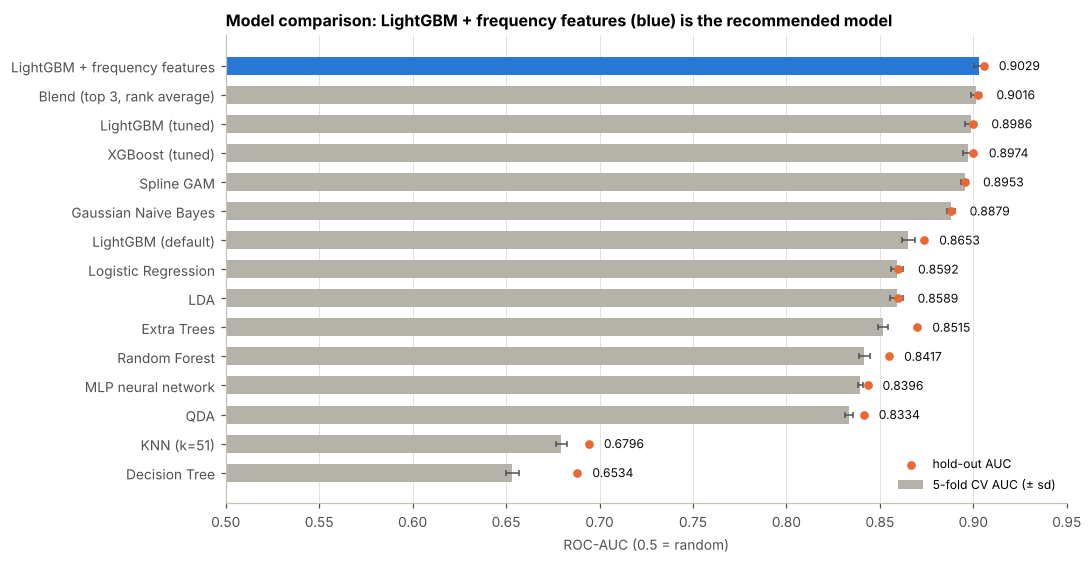

In [39]:
FINAL_NAME = 'LightGBM + frequency features'
plot_df = comparison.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.2))
colors = [BLUE if n == FINAL_NAME else GREY for n in plot_df.index]
ax.barh(plot_df.index, plot_df['CV AUC'] - 0.5, left=0.5, xerr=plot_df['CV AUC sd'], color=colors, height=0.62,
        error_kw=dict(ecolor='#52514e', lw=1, capsize=2), label='5-fold CV AUC (± sd)')
ax.scatter(plot_df['hold-out AUC'], plot_df.index, color=ORANGE, s=22, zorder=3, label='hold-out AUC')
for i, (n, row) in enumerate(plot_df.iterrows()):
    ax.text(max(row['CV AUC'] + row['CV AUC sd'], row['hold-out AUC']) + 0.008, i, f'{row["CV AUC"]:.4f}', va='center', fontsize=8, color=INK)
ax.set_xlim(0.5, 0.95); ax.set_xlabel('ROC-AUC (0.5 = random)')
ax.set_title(f'Model comparison: {FINAL_NAME} (blue) is the recommended model')
ax.legend(loc='lower right', fontsize=8); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

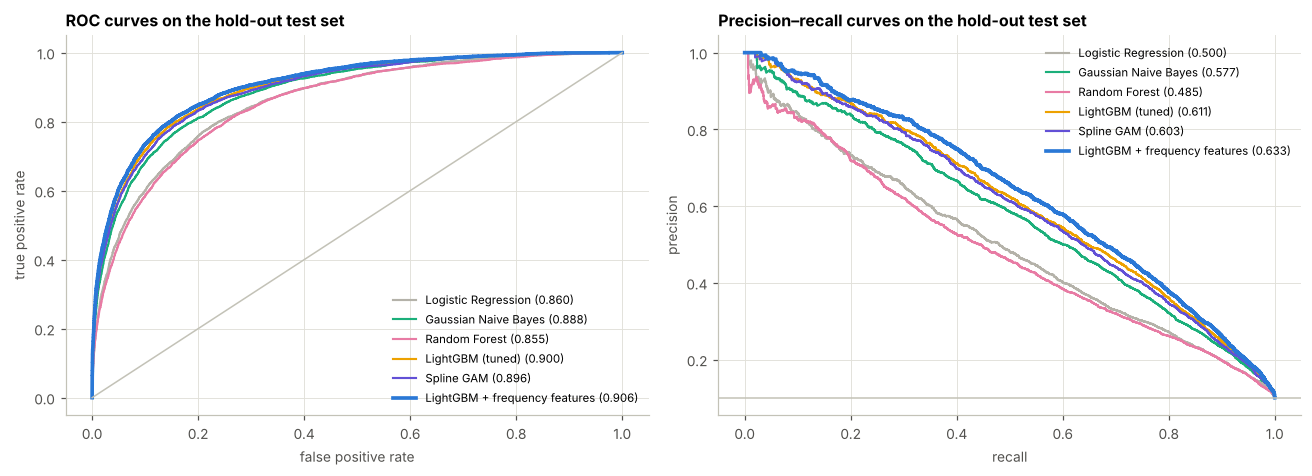

In [40]:
curve_models = ['Logistic Regression', 'Gaussian Naive Bayes', 'Random Forest', 'LightGBM (tuned)', 'Spline GAM', FINAL_NAME]
palette = ['#b4b2a9', '#1baf7a', '#e87ba4', '#eda100', '#6250d6', BLUE]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for name, col in zip(curve_models, palette):
    p = results[name]['test']
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    lw = 2.4 if name == FINAL_NAME else 1.4
    axes[0].plot(fpr, tpr, color=col, lw=lw, label=f'{name} ({roc_auc_score(y_test, p):.3f})')
    axes[1].plot(rec, prec, color=col, lw=lw, label=f'{name} ({average_precision_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], color='#c3c2b7', lw=1)
axes[0].set_title('ROC curves on the hold-out test set'); axes[0].set_xlabel('false positive rate'); axes[0].set_ylabel('true positive rate')
axes[1].axhline(y_test.mean(), color='#c3c2b7', lw=1)
axes[1].set_title('Precision–recall curves on the hold-out test set'); axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
axes[0].legend(fontsize=7.5, loc='lower right'); axes[1].legend(fontsize=7.5, loc='upper right')
plt.tight_layout(); plt.show()

**Reading the results.**
* **The ranking matches the data analysis.** At the top are models that build a flexible, *additive* score from all 200 features: boosted shallow trees, the spline GAM and Gaussian Naive Bayes (0.888–0.903). Linear models sit in the middle (0.859), because they cannot bend each feature's curve. At the bottom are models that rely on interactions or on distances between customers: Random Forest 0.842, MLP 0.840, KNN 0.680 and a single tree 0.653. In 200 independent dimensions a customer's "nearest neighbours" are hardly nearer than random customers, and deep trees spend their splits on interactions that do not exist.
* **Tuning matters for boosting.** The same LightGBM goes from 0.8653 (default, 31 leaves) to 0.8986 (stumps).
* **The frequency features give the best model:** CV AUC 0.9029 ± 0.0023 and hold-out AUC 0.9057. On the corrected t-test it is significantly better than every other model (p ≤ 0.036), including the tuned LightGBM without counts (p = 0.004) and XGBoost (p = 0.0006).
* **Blending does not help.** The rank average of the top 3 (0.9016) is *below* the best single model, because the other two members lack the frequency information and dilute it.
* **Why some hold-out AUCs are higher than their CV AUCs:** the hold-out prediction averages the 5 fold models, which makes it a small ensemble. Averaging helps high-variance models most: Decision Tree +0.035, Extra Trees +0.019, Random Forest +0.013. Stable models (LR, GAM, Naive Bayes) score almost the same in CV and on the hold-out set, which confirms that the test split is representative.

## 7. Final model: evaluation on the hold-out test set
### 7.1 Decision threshold
The model outputs a probability. To turn it into a yes/no decision, the threshold that maximises F1 is chosen on the **out-of-fold** training predictions (never on the test set). It is then applied unchanged to the test set. In practice, the bank may prefer to contact a fixed share of customers instead (see 7.2).

F1-maximising threshold on out-of-fold predictions: 0.256 (OOF F1 = 0.583)

Hold-out test set, threshold 0.50: precision 0.792, recall 0.348, F1 0.483, customers flagged 4.4%

Hold-out test set, threshold 0.256 (chosen): precision 0.576, recall 0.603, F1 0.589, customers flagged 10.5%

Classification report at the chosen threshold:
                precision    recall  f1-score   support

No transaction      0.955     0.950     0.953     35980
   Transaction      0.576     0.603     0.589      4020

      accuracy                          0.915     40000
     macro avg      0.766     0.777     0.771     40000
  weighted avg      0.917     0.915     0.916     40000



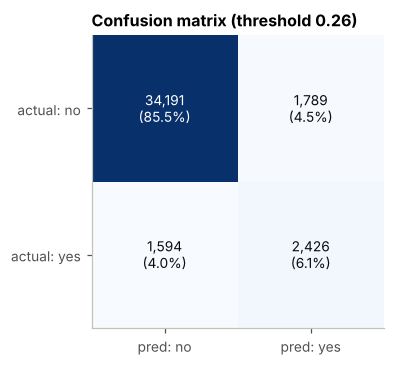

In [41]:
final = results[FINAL_NAME]
prec, rec, thr = precision_recall_curve(y_train, final['oof'])
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
THRESHOLD = float(thr[np.argmax(f1[:-1])])
print(f'F1-maximising threshold on out-of-fold predictions: {THRESHOLD:.3f} (OOF F1 = {f1[:-1].max():.3f})')

p_test = final['test']
for label, th in [('threshold 0.50', 0.5), (f'threshold {THRESHOLD:.3f} (chosen)', THRESHOLD)]:
    pred = (p_test >= th).astype(int)
    print(f'\nHold-out test set, {label}: precision {precision_score(y_test, pred):.3f}, recall {recall_score(y_test, pred):.3f}, '
          f'F1 {f1_score(y_test, pred):.3f}, customers flagged {pred.mean():.1%}')
pred_final = (p_test >= THRESHOLD).astype(int)
print('\nClassification report at the chosen threshold:')
print(classification_report(y_test, pred_final, target_names=['No transaction', 'Transaction'], digits=3))

cm = confusion_matrix(y_test, pred_final)
fig, ax = plt.subplots(figsize=(4.2, 3.4))
ax.imshow(cm, cmap='Blues'); ax.grid(False)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f'{v:,}\n({v / cm.sum():.1%})', ha='center', va='center', color='white' if v > cm.max() / 2 else INK, fontsize=9)
ax.set_xticks([0, 1], ['pred: no', 'pred: yes']); ax.set_yticks([0, 1], ['actual: no', 'actual: yes'])
ax.set_title(f'Confusion matrix (threshold {THRESHOLD:.2f})')
plt.tight_layout(); plt.show()

### 7.2 Who should the bank contact? Gains and lift
Customers are sorted by predicted probability and split into 10 equal groups (deciles). The table shows the share of all transacting customers found in the top *k* % of the list, and how much better that is than contacting customers at random (lift).

,customers,transactions found,% of all transactions captured,precision in group %,lift
top % of customers contacted,,,,,
10,4000,2349,58.43,58.73,5.84
20,8000,3162,78.66,39.52,3.93
30,12000,3515,87.44,29.29,2.91
40,16000,3704,92.14,23.15,2.30
50,20000,3830,95.27,19.15,1.91
60,24000,3914,97.36,16.31,1.62
70,28000,3958,98.46,14.14,1.41
80,32000,3990,99.25,12.47,1.24
90,36000,4015,99.88,11.15,1.11


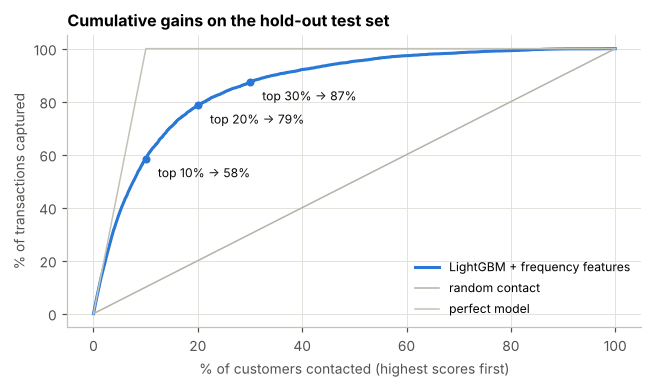

In [42]:
order_ = np.argsort(-p_test)
y_sorted = y_test[order_]
n = len(y_sorted)
gains = []
for k in range(1, 11):
    top = y_sorted[: int(round(n * k / 10))]
    gains.append({'top % of customers contacted': k * 10, 'customers': len(top), 'transactions found': int(top.sum()),
                  '% of all transactions captured': 100 * top.sum() / y_test.sum(),
                  'precision in group %': 100 * top.mean(), 'lift': top.mean() / y_test.mean()})
gains = pd.DataFrame(gains).set_index('top % of customers contacted')
display(gains.round(2))

fig, ax = plt.subplots(figsize=(6, 3.6))
x = np.arange(1, n + 1) / n * 100
ax.plot(x, np.cumsum(y_sorted) / y_test.sum() * 100, color=BLUE, label=FINAL_NAME)
ax.plot([0, 100], [0, 100], color=GREY, lw=1, label='random contact')
ax.plot([0, y_test.mean() * 100, 100], [0, 100, 100], color='#c3c2b7', lw=1, label='perfect model')
for k in [10, 20, 30]:
    v = gains.loc[k, '% of all transactions captured']
    ax.annotate(f'top {k}% → {v:.0f}%', (k, v), xytext=(8, -12), textcoords='offset points', fontsize=8, color=INK)
    ax.scatter([k], [v], color=BLUE, s=18, zorder=3)
ax.set_xlabel('% of customers contacted (highest scores first)'); ax.set_ylabel('% of transactions captured')
ax.set_title('Cumulative gains on the hold-out test set'); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

### 7.3 How certain are the hold-out numbers? Bootstrap confidence intervals
The test set is resampled 1,000 times. Two quantities are tracked: the final model's AUC, and its AUC gain over the tuned LightGBM without frequency features (a paired comparison on the same customers).

In [43]:
rng = np.random.default_rng(SEED)
p_base = results['LightGBM (tuned)']['test']
boot_auc, boot_diff = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    a = roc_auc_score(y_test[idx], p_test[idx])
    boot_auc.append(a); boot_diff.append(a - roc_auc_score(y_test[idx], p_base[idx]))
lo, hi = np.percentile(boot_auc, [2.5, 97.5])
dlo, dhi = np.percentile(boot_diff, [2.5, 97.5])
print(f'Final model hold-out AUC {roc_auc_score(y_test, p_test):.4f}, 95% CI [{lo:.4f}, {hi:.4f}]')
print(f'Gain over tuned LightGBM without frequency features: {np.mean(boot_diff):+.4f}, 95% CI [{dlo:+.4f}, {dhi:+.4f}], '
      f'share of resamples with a gain: {np.mean(np.array(boot_diff) > 0):.1%}')

Final model hold-out AUC 0.9057, 95% CI [0.9009, 0.9105]
Gain over tuned LightGBM without frequency features: +0.0060, 95% CI [+0.0051, +0.0069], share of resamples with a gain: 100.0%


### 7.4 Calibration: can the probabilities be trusted?

Brier score 0.0569 (always predicting the base rate gives 0.0904)
Mean predicted probability 0.0982 vs actual transaction rate 0.1005


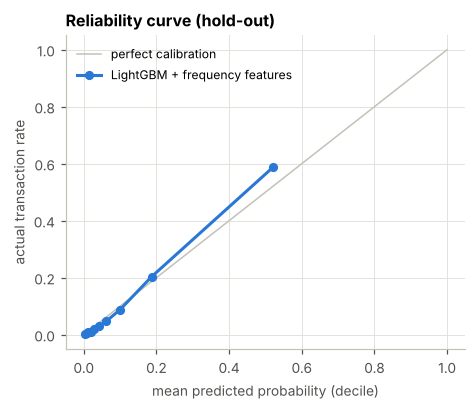

In [44]:
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy='quantile')
print(f'Brier score {brier_score_loss(y_test, p_test):.4f} (always predicting the base rate gives '
      f'{brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.4f})')
print(f'Mean predicted probability {p_test.mean():.4f} vs actual transaction rate {y_test.mean():.4f}')
fig, ax = plt.subplots(figsize=(4.4, 3.8))
ax.plot([0, 1], [0, 1], color='#c3c2b7', lw=1, label='perfect calibration')
ax.plot(mean_pred, frac_pos, marker='o', markersize=5, color=BLUE, label=FINAL_NAME)
ax.set_xlabel('mean predicted probability (decile)'); ax.set_ylabel('actual transaction rate')
ax.set_title('Reliability curve (hold-out)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7.5 What drives the predictions?
Importance is the total split gain of each original feature, adding its value column and its count column, averaged over the five fold models. Because the model is additive by construction (each tree uses one feature and its count), each feature's contribution to the log-odds can be read directly from LightGBM's `pred_contrib`. The plots show these learned per-feature curves for the four most important features.

Share of total gain from the count columns: 5.6%
Top 20 features account for 29.9% of the gain; top-10 overlap with the top-10 univariate AUC list: 9
Spearman rank correlation of model importance with univariate AUC: 0.98


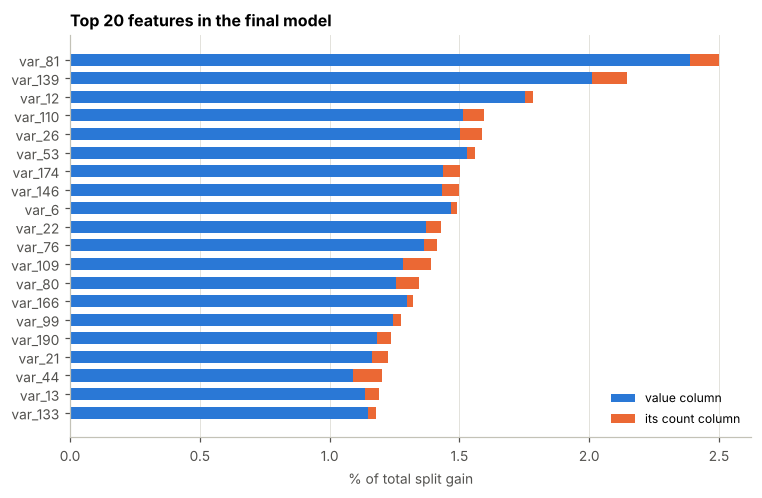

In [45]:
gain_mat = np.mean([m.steps[-1][1].booster_.feature_importance('gain') for m in final['models']], axis=0)
imp = pd.DataFrame({'value_gain': gain_mat[:200], 'count_gain': gain_mat[200:]}, index=features)
imp['total_gain'] = imp.value_gain + imp.count_gain
imp['share_%'] = 100 * imp.total_gain / imp.total_gain.sum()
imp = imp.sort_values('total_gain', ascending=False)
print(f'Share of total gain from the count columns: {100 * imp.count_gain.sum() / imp.total_gain.sum():.1f}%')
print(f'Top 20 features account for {imp["share_%"].head(20).sum():.1f}% of the gain; '
      f'top-10 overlap with the top-10 univariate AUC list: {len(set(imp.index[:10]) & set(ft.index[:10]))}')
print(f'Spearman rank correlation of model importance with univariate AUC: '
      f'{stats.spearmanr(imp.total_gain, ft.loc[imp.index, "univariate_auc"])[0]:.2f}')

top20 = imp.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(top20.index, top20.value_gain / imp.total_gain.sum() * 100, color=BLUE, height=0.65, label='value column')
ax.barh(top20.index, top20.count_gain / imp.total_gain.sum() * 100, left=top20.value_gain / imp.total_gain.sum() * 100,
        color=ORANGE, height=0.65, label='its count column')
ax.set_xlabel('% of total split gain'); ax.set_title('Top 20 features in the final model'); ax.legend(fontsize=8, loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

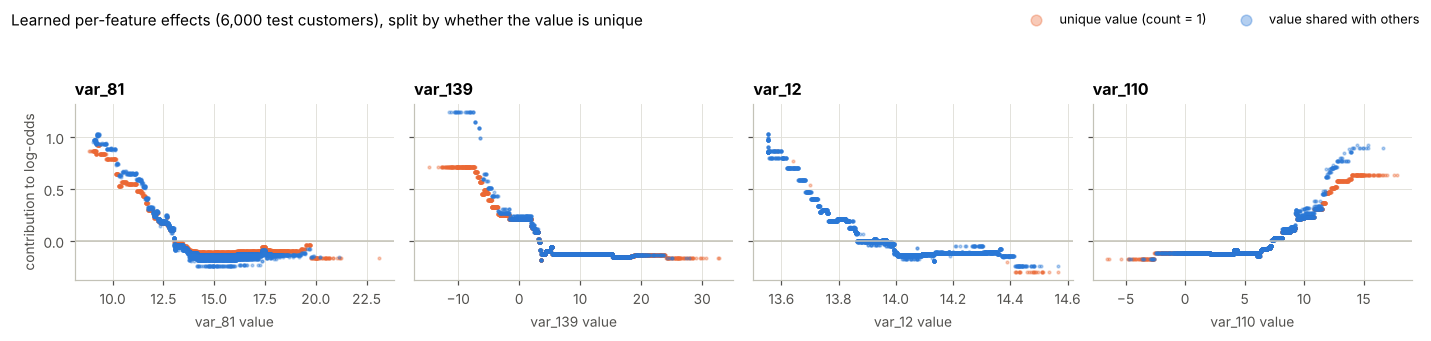

In [46]:
fold_model = final['models'][0]
enc0, booster0 = fold_model.steps[0][1], fold_model.steps[-1][1].booster_
sample = Xte[np.random.default_rng(SEED).choice(len(Xte), min(6000, len(Xte)), replace=False)]
F_s = enc0.transform(sample)
contrib = booster0.predict(F_s, pred_contrib=True)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.1), sharey=True)
for ax, f in zip(axes, imp.index[:4]):
    j = features.index(f)
    effect = contrib[:, j] + contrib[:, j + 200]          # value + its own count = the feature's total contribution
    unique_ = F_s[:, j + 200] <= 1
    ax.scatter(sample[unique_, j], effect[unique_], s=3, alpha=0.35, color=ORANGE, label='unique value (count = 1)')
    ax.scatter(sample[~unique_, j], effect[~unique_], s=3, alpha=0.35, color=BLUE, label='value shared with others')
    ax.axhline(0, color='#c3c2b7', lw=1); ax.set_title(f); ax.set_xlabel(f'{f} value')
axes[0].set_ylabel('contribution to log-odds')
handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle(f'Learned per-feature effects ({len(sample):,} test customers), split by whether the value is unique',
             x=0.01, ha='left', fontsize=10)
plt.tight_layout(rect=(0, 0, 1, 0.92))
fig.legend(handles, labels, loc='upper right', ncol=2, fontsize=8.5, markerscale=4)
plt.show()

**Findings on the hold-out test set** (40,000 customers that were not used for anything before this section):
* **Ranking:** AUC **0.9057** (95 % bootstrap CI 0.9009–0.9105) and PR-AUC 0.633, against a base rate of 0.10. The frequency features add +0.0060 AUC over the same model without them (CI +0.0051 to +0.0069). The gain is positive in all 1,000 bootstrap resamples, so it is real and not an artefact of this split.
* **Decisions:** At the 0.256 threshold (chosen on training data), the model flags 10.5 % of customers. It finds **60.3 % of all transactions** (2,426 of 4,020), and 57.6 % of the flagged customers really transact, 5.7 times the base rate. Overall accuracy is 91.5 %. The default 0.5 threshold would be too strict for this purpose: precision 0.79 but recall only 0.35.
* **Targeting:** Contacting the top 10 % of customers by score reaches **58 % of all transactions** (lift 5.8). The top 20 % reaches 79 % and the top 30 % reaches 87 %.
* **Calibration:** The probabilities are reliable. The Brier score is 0.0569 (0.0904 for a constant guess), and the mean predicted probability (9.8 %) matches the actual rate (10.05 %). The model is slightly under-confident only in the top decile (predicted ≈ 0.52, actual ≈ 0.59). The scores can therefore be used directly as probabilities, for example to estimate how many transactions a campaign will produce.
* **Drivers:** The most important features are the ones found in the univariate analysis: `var_81`, `var_139`, `var_12`, `var_110`, `var_26`, `var_53` (9 of the top 10 overlap; rank correlation 0.98). The count columns supply 5.6 % of the total gain. The learned curves in the last figure reproduce the "flat-then-steep" shapes of Section 3.5. They also show how the count is used: **when a value is unique, the model trusts it less.** The orange curve for unique values is flatter at the extremes. For example, a very low `var_139` adds about +0.7 to the log-odds when the value is unique but about +1.2 when it is shared. In the flat middle region, unique values sit slightly higher.

## 8. Production model
The recommended pipeline (`ValueCountEncoder` → LightGBM) is re-trained on **all 200,000 customers**. The data is now 1.56× larger than a CV training fold, so the number of boosting rounds is raised by 20 % over the tuned value (a common rule of thumb). The fitted pipeline, the decision threshold and the metadata are saved in one file, which is then reloaded to score customers the way a production job would.

In [47]:
PROD_ROUNDS = int(round(CNT_ROUNDS * 1.2))
t = time.time()
production_model = make_pipeline(ValueCountEncoder(), lgbm(n_estimators=PROD_ROUNDS, **CNT_PARAMS))
production_model.fit(X_all.to_numpy(), y_all)
print(f'Production model trained on {len(y_all):,} customers with {PROD_ROUNDS} rounds in {time.time() - t:.0f}s')

bundle = {
    'model': production_model,
    'threshold': THRESHOLD,
    'features': features,
    'model_name': FINAL_NAME,
    'cv_auc': float(results[FINAL_NAME]['fold_auc'].mean()),
    'holdout_auc': float(roc_auc_score(y_test, p_test)),
    'trained_rows': int(len(y_all)),
    'versions': {'lightgbm': lgb.__version__, 'sklearn': sklearn.__version__, 'numpy': np.__version__},
    'note': 'Input: the 200 raw var_* columns. Output: probability of a transaction; flag = probability >= threshold. '
            'Intended for NEW customers (the count lookup adds 1 for the scored customer).',
}
MODEL_FILE = 'customer_transaction_model.joblib'
joblib.dump(bundle, MODEL_FILE, compress=3)
print(f'Saved {MODEL_FILE} ({os.path.getsize(MODEL_FILE) / 1e6:.1f} MB)')

Production model trained on 200,000 customers with 2647 rounds in 86s


Saved customer_transaction_model.joblib (34.9 MB)


In [48]:
def score_customers(new_customers: pd.DataFrame, bundle: dict) -> pd.DataFrame:
    # Score new customers with the saved production bundle
    missing = set(bundle['features']) - set(new_customers.columns)
    if missing:
        raise ValueError(f'Missing feature columns: {sorted(missing)[:5]} ...')
    X_new = new_customers[bundle['features']].astype(np.float32).to_numpy()
    if not np.isfinite(X_new).all():
        raise ValueError('Input contains missing or infinite values')
    proba = bundle['model'].predict_proba(X_new)[:, 1]
    return pd.DataFrame({'ID_code': new_customers['ID_code'].values,
                         'transaction_probability': proba.round(4),
                         'predicted_transaction': (proba >= bundle['threshold']).astype(int)})

loaded = joblib.load(MODEL_FILE)
t = time.time(); loaded['model'].predict_proba(Xte)
print(f'Scoring speed: {len(Xte) / (time.time() - t):,.0f} customers per second')
print(f"Reloaded: {loaded['model_name']}, threshold {loaded['threshold']:.3f}, CV AUC {loaded['cv_auc']:.4f}, "
      f"hold-out AUC {loaded['holdout_auc']:.4f}")
example = df.sample(8, random_state=1)        # demonstration only: these customers were part of the training data
out = score_customers(example, loaded)
out['actual_target'] = example['target'].values
out

Scoring speed: 15,107 customers per second
Reloaded: LightGBM + frequency features, threshold 0.256, CV AUC 0.9029, hold-out AUC 0.9057


,ID_code,transaction_probability,predicted_transaction,actual_target
0,train_49673,0.0261,0,0
1,train_171551,0.0030,0,0
2,train_5506,0.1501,0,0
3,train_38370,0.0650,0,0
4,train_36930,0.0030,0,0
5,train_167783,0.0452,0,0
6,train_67487,0.0282,0,0
7,train_101486,0.5237,1,1


## 9. Model comparison report

### 9.1 Results (5-fold CV on 160,000 training customers; hold-out = 40,000 untouched customers)

| Rank | Model | Family | CV ROC-AUC (± sd) | Hold-out ROC-AUC | Hold-out PR-AUC | Fit time / fold* |
|---|---|---|---|---|---|---|
| 1 | **LightGBM + frequency features** | Engineered features | **0.9029 ± 0.0023** | **0.9057** | **0.633** | 60 s |
| 2 | Blend of top 3 (rank average) | Ensemble | 0.9016 ± 0.0028 | 0.9025 | 0.621 | 147 s |
| 3 | LightGBM (tuned: stumps) | Boosting | 0.8986 ± 0.0030 | 0.8997 | 0.611 | 26 s |
| 4 | XGBoost (tuned: depth 2) | Boosting | 0.8974 ± 0.0029 | 0.8998 | 0.612 | 61 s |
| 5 | Spline GAM | Additive | 0.8953 ± 0.0019 | 0.8957 | 0.603 | 15 s |
| 6 | Gaussian Naive Bayes | Probabilistic | 0.8879 ± 0.0021 | 0.8883 | 0.577 | < 1 s |
| 7 | LightGBM (default settings) | Boosting | 0.8653 ± 0.0036 | 0.8737 | 0.538 | 11 s |
| 8 | Logistic Regression | Linear | 0.8592 ± 0.0032 | 0.8599 | 0.501 | 1 s |
| 9 | LDA | Linear | 0.8589 ± 0.0032 | 0.8598 | 0.500 | 2 s |
| 10 | Extra Trees | Bagging | 0.8515 ± 0.0026 | 0.8701 | 0.521 | 21 s |
| 11 | Random Forest | Bagging | 0.8417 ± 0.0031 | 0.8550 | 0.485 | 44 s |
| 12 | MLP neural network | Neural network | 0.8396 ± 0.0015 | 0.8434 | 0.460 | 7 s |
| 13 | QDA | Probabilistic | 0.8334 ± 0.0021 | 0.8414 | 0.458 | 2 s |
| 14 | KNN (k = 51) | Instance-based | 0.6796 ± 0.0030 | 0.6943 | 0.226 | 51 s |
| 15 | Decision Tree | Single tree | 0.6534 ± 0.0034 | 0.6882 | 0.220 | 29 s |

\* Fit time is for one fold on a 2-core CPU and includes predicting the validation fold and the test set. The blend's time is the sum of its three members.

### 9.2 Recommended model for production: **LightGBM + frequency features**

**Why this model**
1. **Best performance, and the lead is statistically sound.** It has the highest CV AUC and the highest hold-out AUC, and it is significantly better than every alternative: corrected t-test p ≤ 0.036, and a bootstrap gain over the tuned LightGBM of +0.006 that is positive in 100 % of resamples.
2. **It matches the structure of the data.** It is additive across the 200 independent features, flexible within each feature, and it uses the value-frequency signal found in the analysis.
3. **Reliable probabilities.** It is well calibrated (Brier 0.057), so the scores can be used as probabilities or for ranking without re-calibration.
4. **Practical to run.** Training on all 200,000 customers takes about 1.5 minutes on a 2-core CPU, and scoring runs at about 15,000 customers per second. The whole model is one scikit-learn pipeline (encoder + LightGBM), saved in a single 35 MB file.
5. **Clear business value.** Contacting the top 10 % of customers by score reaches 58 % of all transacting customers, 5.8 times better than random contact. At the F1-optimal threshold it finds 60 % of transactions with 58 % precision.

**Alternatives worth keeping**
* **Tuned LightGBM without frequency features** (AUC 0.8986) is the fallback if the value-count table cannot be maintained. It is simpler and smaller (no lookup table) and only 0.004–0.006 AUC behind.
* **Gaussian Naive Bayes** (AUC 0.888) works as a sanity-check baseline. It trains in under a second, has no hyperparameters and is fully transparent.

**Not recommended:** KNN, the single decision tree, Random Forest and the MLP are slower and/or 0.06–0.25 AUC worse, because they rely on interactions or distances that this data does not have. The blend adds complexity and scores below the best single model.

**Production notes**
* Score new customers with the saved bundle and `score_customers()` (Section 8). Use the 0.256 threshold for a yes/no flag, or rank customers and contact the top *k* % that the campaign budget allows.
* The frequency encoder relies on the value-count table of the training data, which is stored inside the model file. Refresh it whenever the model is retrained, because value frequencies depend on the customer base.
* Monitor the AUC on newly labelled customers and the share of "unique" values per feature (32 % in training). A drift in either is a signal to retrain.

## 10. Report on challenges faced

| # | Challenge | What was observed | Technique used | Reason and result |
|---|---|---|---|---|
| 1 | **Anonymised features** | 200 columns with no names or business meaning | Statistical profiling instead of domain reasoning: univariate AUC, KS tests, binned transaction rates, correlation, PCA, value frequencies | The *structure* of the data (independent features, weak additive signals) drove the model design, since the meaning of the features is unknown |
| 2 | **Class imbalance** (10 % transact) | Always predicting "no" is 89.95 % accurate | ROC-AUC and PR-AUC as metrics; stratified splits and folds; no re-sampling; threshold chosen on out-of-fold predictions | Class weights and under-sampling did not improve AUC and doubled log loss. SMOTE dropped LightGBM to AUC 0.80. Moving the threshold gives the same precision / recall trade-off without distorting the probabilities |
| 3 | **Weak signal spread over 200 features** | Best single-feature AUC 0.568; 45 features not significant | Keep all features; use models that sum many small effects | Dropping the weak features cost 0.0011 AUC |
| 4 | **Non-linear per-feature effects** | "Flat-then-steep" curves | Spline GAM; boosted stumps | Logistic regression 0.859 → GAM 0.895 → boosted stumps 0.899 |
| 5 | **Independent features, so standard models over-fit interactions** | Max \|r\| 0.0098, flat PCA; default LightGBM only 0.865 | Tuned tree size: 2 leaves per tree (stumps) and 5 % of features per tree | +0.033 AUC over default LightGBM. Larger trees spend splits on interactions that do not exist |
| 6 | **Hidden signal in value frequency** | Unique values have a higher transaction rate in 166 of 200 features | `ValueCountEncoder` + LightGBM interaction constraints (each feature may only interact with its own count) | +0.0043 CV AUC and +0.006 hold-out AUC (CI +0.005 to +0.007). Unconstrained counts gave nothing |
| 7 | **Leakage risk from the engineered features** | Counts computed on all data would leak information from the validation and test rows | The encoder is a scikit-learn transformer, re-fitted inside every fold; new rows get "training count + 1" | CV and hold-out scores stay honest, and the same code runs in production |
| 8 | **Large data on limited hardware** (200,000 × 200 values, 2 CPU cores) | KNN and Random Forest are slow; the GAM is memory-heavy | float32 (half the memory); histogram-based boosting; early stopping on an inner split, then a fixed number of rounds in CV; lighter Random Forest / Extra Trees settings; test predictions averaged from the fold models instead of refitting | The whole notebook runs in about 40–45 minutes on a 2-core CPU |
| 9 | **Choosing between models with small differences** | Top models within 0.005 AUC of each other | Same 5 folds for every model; Nadeau–Bengio corrected t-test; bootstrap confidence intervals on the hold-out set | Confirms the final model's lead is real (p ≤ 0.036; gain positive in 100 % of bootstrap resamples) |
| 10 | **Outliers** | 12.5 % of customers have at least one | Kept, with no capping or removal | Customers with outliers transact more (12.0 % vs 9.8 %), so the extreme values carry signal |
| 11 | **Ideas that did not pay off** | — | Within-class shuffle augmentation, blending, feature selection | +0.0004, −0.0013 and −0.0011 AUC respectively. All rejected to keep the production model simple |

## 11. Conclusion

* **Task 1 (data analysis):** The data is clean (no missing values or duplicates) but hard to model. Only 10 % of customers transact, every feature is weak on its own (best AUC 0.568), and the 200 features are independent of each other, with monotonic but non-linear effects. How often a value occurs carries a small extra signal.
* **Task 2 (predictive model):** These findings led to an additive model: LightGBM with single-split trees, where each feature is paired with its own value count. It reaches **ROC-AUC 0.903 in cross-validation and 0.906 on the untouched test set**. At the chosen threshold it finds 60 % of transacting customers with 58 % precision, and the top 10 % of scores contain 58 % of all transactions.
* **Model comparison:** 14 models (plus a blend) were compared on identical folds. The recommended model is significantly better than all of them. The tuned LightGBM without frequency features is a simpler fallback.
* **Production:** The final pipeline was trained on all 200,000 customers, saved with its threshold as `customer_transaction_model.joblib`, reloaded, and used through `score_customers()`.
* **Next steps:** (1) Validate on a later time period. The data has no dates, so drift over time could not be tested. (2) Set the contact threshold from the real cost of a contact and the value of a transaction. (3) Retrain regularly and refresh the value-count table each time.

In [49]:
print(f'Total notebook run time: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes')

Total notebook run time: 42.1 minutes
